# Name That LLM — ARTI 450 Project 1
### Dataset exploration, feature selection, traditional classifiers, and a compliant Keras MLP

**Team:** Garrett Ford, Ferris Farmer, and Caden Raleigh  
**Goal:** Predict which of 18 known large language models produced a response (multiclass classification), rather than distinguish AI text from human text.

**Reading guide:** Sections 1–8 contain the team's original data processing and traditional-model work. Section 9A preserves the earlier scikit-learn MLP as *exploratory baseline work*, but **it is not the required final deep-learning model**. Section 9B introduces the required Keras neural network with two hidden layers. Section 10B generates the **final six-row held-out test comparison**, confusion matrices, and results for the report. The original outputs from the baseline remain for traceability; final claims must come from newly executed Section 10B.

**Before running:** Keep `train.csv` in the same folder as this notebook. Install dependencies in your Jupyter environment (Keras with a TensorFlow or PyTorch backend). Run **Kernel → Restart Kernel and Run All Cells** so the split, transformations, and final evaluation are created in order.


**Before running on another computer:** Open a terminal in the repository folder, install dependencies with `python -m pip install -r requirements.txt`, and launch Jupyter from that same folder. The dataset is loaded with `pd.read_csv("train.csv")` and does not require a computer-specific path.

## 1. Load and Inspect the Dataset

In [3]:
import pandas as pd

df = pd.read_csv("train.csv")

print("Rows and columns:", df.shape)
print("Unique prompts:", df["prompt_id"].nunique())
print("Unique LLMs:", df["model"].nunique())
df.head(3)

Rows and columns: (2699, 4)
Unique prompts: 150
Unique LLMs: 18


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash


## 2. Data Quality Checks

In [4]:
print("Missing values by column:")
print(df.isna().sum())

print("\nBlank passages:", df["text"].fillna("").str.strip().eq("").sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate passages:", df["text"].duplicated().sum())

print("\nPassages per LLM:")
print(df["model"].value_counts())

Missing values by column:
id           0
prompt_id    0
text         0
model        0
dtype: int64

Blank passages: 0
Duplicate rows: 0
Duplicate passages: 0

Passages per LLM:
model
qwen3.8-max               150
claude-sonnet-5           150
glm-5.3                   150
gpt-6-astra               150
gpt-5.5                   150
kimi-k3                   150
claude-opus-5             150
gemini-3.7-flash          150
claude-opus-4-8           150
gpt-5.6-luna              150
claude-opus-4-6           150
gemini-3.8-flash          150
gemini-3.1-pro-preview    150
glm-5.3-flash             150
gpt-5.6-terra             150
gemini-3.6-flash          150
gpt-5.6-sol               150
claude-fable-5            149
Name: count, dtype: int64


There are no missing values, blank passages, or duplicates. Each LLM has 150 passages except for one so the classes are well balanced already. No rows are needed to be removed.

## 3. Exploratory Data Analysis

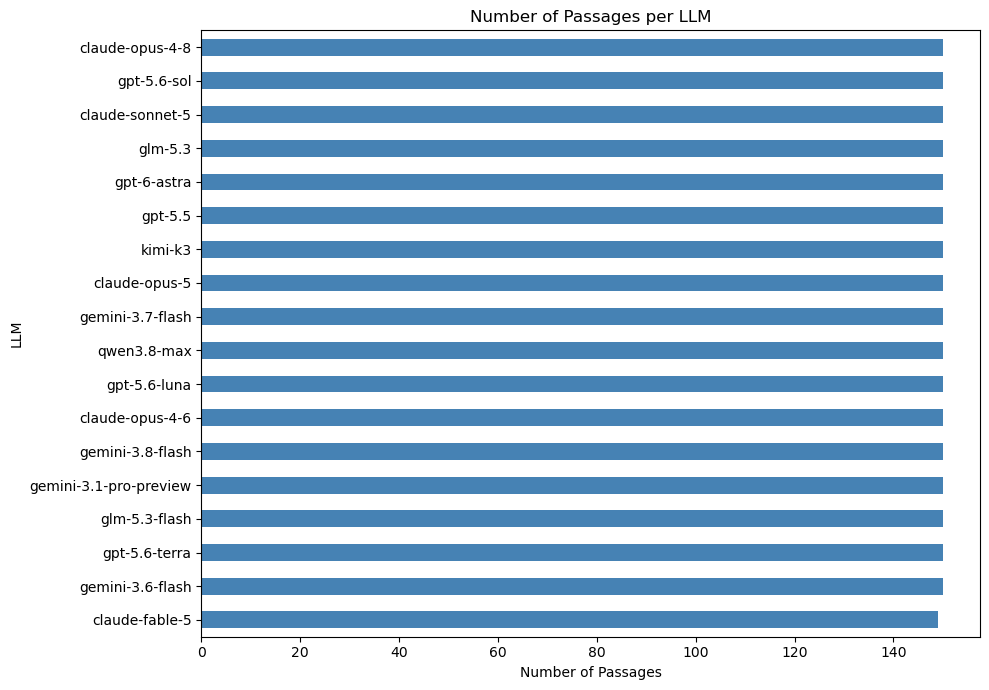

In [5]:
import matplotlib.pyplot as plt

model_counts = df["model"].value_counts().sort_values()

model_counts.plot(kind="barh", figsize=(10, 7), color="steelblue")

plt.title("Number of Passages per LLM")
plt.xlabel("Number of Passages")
plt.ylabel("LLM")
plt.tight_layout()
plt.show()

Passage length statistics:
count    2699.000000
mean      114.659504
std        58.281372
min        36.000000
25%        64.000000
50%       101.000000
75%       157.000000
max       274.000000
Name: word_count, dtype: float64


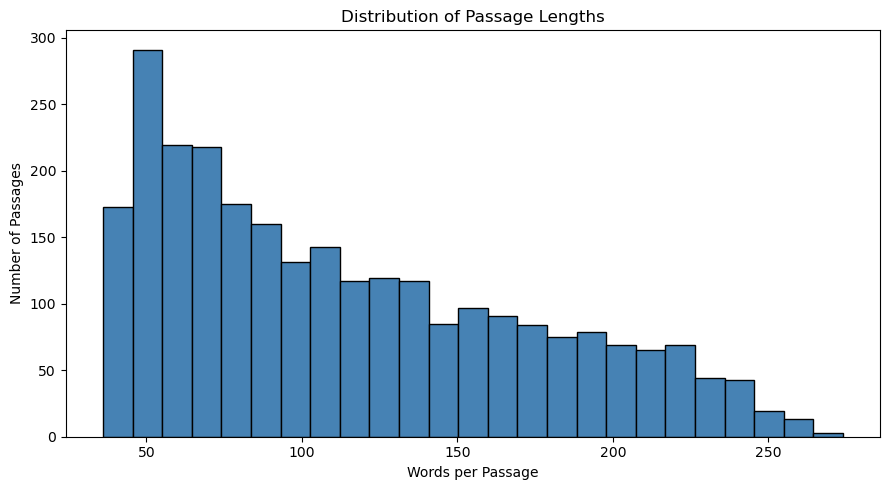

In [6]:
# Count the words in each passage
df["word_count"] = df["text"].str.split().str.len()

print("Passage length statistics:")
print(df["word_count"].describe())

# Show the distribution of passage lengths
plt.figure(figsize=(9, 5))
plt.hist(df["word_count"], bins=25, color="steelblue", edgecolor="black")

plt.title("Distribution of Passage Lengths")
plt.xlabel("Words per Passage")
plt.ylabel("Number of Passages")
plt.tight_layout()
plt.show()

The passages from the dataset range from 36 to 274 words, with an average of about 115 words. The median is 101 words, and the middle 50% fall between 64 and 157 words. Shorter passages are more common than longer ones.

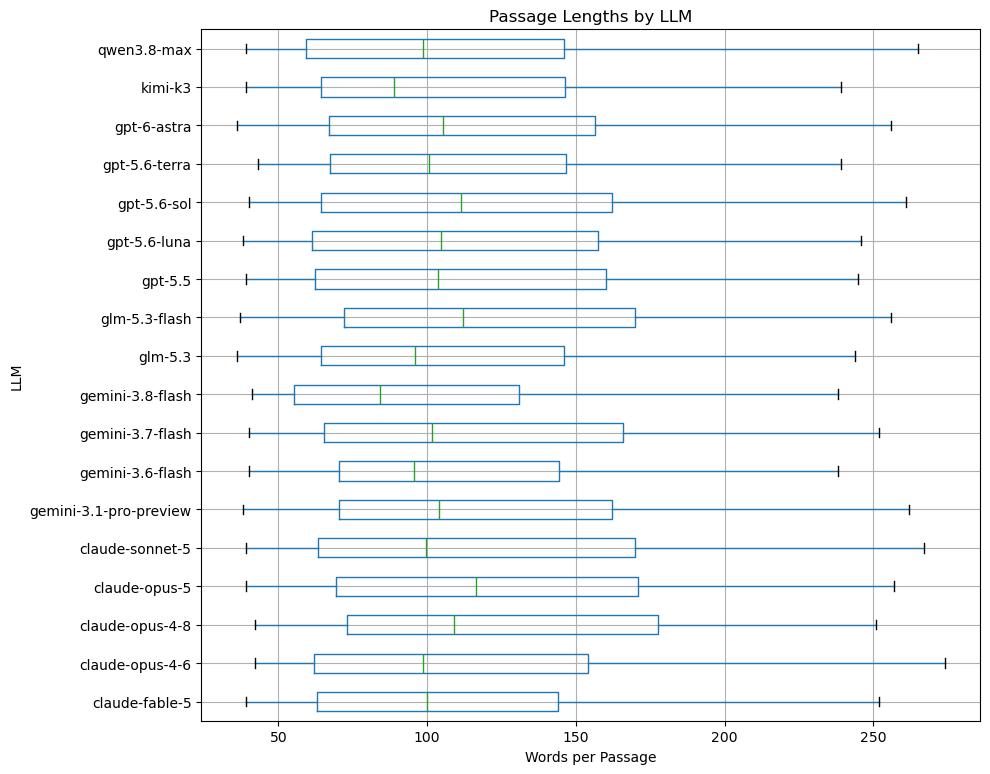

In [7]:
df.boxplot(
    column="word_count",
    by="model",
    vert=False,
    figsize=(10, 8)
)

plt.title("Passage Lengths by LLM")
plt.suptitle("")
plt.xlabel("Words per Passage")
plt.ylabel("LLM")
plt.tight_layout()
plt.show()

In [8]:
# Display the two shortest and two longest passages
columns = ["model", "word_count", "text"]

with pd.option_context("display.max_colwidth", None):
    print("Shortest passages:")
    display(df.nsmallest(2, "word_count")[columns])

    print("Longest passages:")
    display(df.nlargest(2, "word_count")[columns])

Shortest passages:


,model,word_count,text
1436,gpt-6-astra,36,"Data science communities connect people who share knowledge, solve problems, and learn from diverse perspectives. They foster collaboration, encourage ethical practices, and make tools more accessible, helping both newcomers and experts turn data into real-world impact."
2511,glm-5.3,36,"Beneath crushing darkness, life learned to weave light—jellyfish pulsing sapphire, anglerfish dangling false moons. Why countless species independently conjured this cold chemistry remains evolution's riddle, yet in that black cathedral, glowing silence answers with unbearable beauty."


Longest passages:


,model,word_count,text
2329,claude-opus-4-6,274,"The audience can see the letter on the table — they have watched Lady Harwick place it there with trembling, deliberate hands, the letter that confesses everything, that names her lover, that begs forgiveness in language so raw it will unmake a marriage of twenty years — and now they hear Edmund's boots in the corridor, his cheerful whistling, the sound of a man who believes he is coming home to an ordinary evening of wine and familiar silence. He pauses at the doorway to remove his coat. He comments on the rain. He crosses to the fire and warms his palms, standing with his back to the table, inches from the pale envelope, and the audience holds its collective breath like a single organism gripping the armrests of five hundred seats, because they know what he does not: that the moment he turns, the moment his idle gaze falls upon that cream-colored rectangle propped against the candlestick, his understanding of every tender word his wife has spoken for three years will curdle into ash. He is talking now about the garden, about the roses he intends to plant in spring, about how he imagines the two of them growing old among flowers, and every sweet domestic detail is a nail driven deeper into the coffin of his innocence. The audience wants to scream. They want to rush the stage, seize the letter, feed it to the fire before his eyes find it. But theater is the cruelest contract: they must sit, and watch, and know, while Edmund — dear, doomed, whistling Edmund — finally turns toward the table and reaches for the light."
1280,claude-sonnet-5,267,"Beneath the sun-scorched hills of southeastern Anatolia, where the Tigris and Euphrates trace their ancient courses toward Mesopotamia, lies a monument that unravels the tidy narrative of human origins: Göbekli Tepe, raised some eleven and a half millennia ago by hands that had never sown a seed nor fired a pot. Here, hunter-gatherers—bands presumed too primitive for grand ambition—dragged and hewed limestone pillars weighing many tons, arranging them into concentric rings whose T-shaped megaliths loom like watchful ancestors or forgotten gods. Across their surfaces creep a menagerie of the wild: foxes crouch mid-stride, boars bare their tusks, serpents coil in endless knots, scorpions scuttle beside cranes and vultures whose wings seem poised for flight. These are not the tame beasts of pasture but the untamed terrors and totems of a world still ruled by instinct and myth, rendered with a sculptural sophistication that defies the era's supposed simplicity. No hearths, no houses, no granaries mark this place as domestic; it was a sanctuary, perhaps a necropolis of the spirit, where scattered peoples converged from distant valleys to feast, to labor collectively, and to commune with forces beyond survival. That such coordination—the quarrying, the transport, the carving—preceded the plow and the potter's wheel suggests that ritual, not agriculture, may have first drawn scattered humanity into settled cooperation, that belief itself laid the cornerstone of civilization. Buried deliberately beneath tons of backfilled rubble millennia after its raising, as though intentionally returned to earth, Göbekli Tepe endures as a silent, stone-carved testament to a spiritual awakening older than the hearth, older than the harvest, older than history's first recorded word."


I wanted to look at some of the passages to check for data problems or incomplete responses, so I took the 2 longest and shortest passages to check and everything checked out. The lengths alone aren't a reason to remove as they can help with predictablility.

## 4. Training Validation and Test Splits

In [9]:
from sklearn.model_selection import train_test_split

# Assign 70% of the prompts to training
prompt_ids = df["prompt_id"].drop_duplicates().to_numpy()

train_prompts, remaining_prompts = train_test_split(
    prompt_ids,
    test_size=0.30,
    random_state=42
)

# Divide the remaining prompts between validation and testing
val_prompts, test_prompts = train_test_split(
    remaining_prompts,
    test_size=0.50,
    random_state=42
)

# Collect the passages belonging to each group
train_df = df[df["prompt_id"].isin(train_prompts)].copy()
val_df = df[df["prompt_id"].isin(val_prompts)].copy()
test_df = df[df["prompt_id"].isin(test_prompts)].copy()

# Verify that no prompt appears in multiple sets
assert set(train_prompts).isdisjoint(val_prompts)
assert set(train_prompts).isdisjoint(test_prompts)
assert set(val_prompts).isdisjoint(test_prompts)

# Show the size and class coverage of each set
for name, split in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(split)} passages, "
        f"{split['prompt_id'].nunique()} prompts, "
        f"{split['model'].nunique()} LLMs"
    )

print("\nNo prompt overlap between sets.")

Training: 1890 passages, 105 prompts, 18 LLMs
Validation: 396 passages, 22 prompts, 18 LLMs
Test: 413 passages, 23 prompts, 18 LLMs

No prompt overlap between sets.


We split the data by prompt ID into approximately 70% training, 15% validation, and 15% testing. Each set contains all 18 LLMs, and no prompt appears in more than one set. This lets us evaluate performance on responses to unseen prompts.

## 5. Text Features and Preprocessing

In [10]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(train_df["model"].to_numpy())
y_val = label_encoder.transform(val_df["model"].to_numpy())
y_test = label_encoder.transform(test_df["model"].to_numpy())

# Show which number represents each LLM
label_mapping = pd.DataFrame({
    "LLM": label_encoder.classes_,
    "Numeric Label": range(len(label_encoder.classes_))
})

display(label_mapping)

,LLM,Numeric Label
0,claude-fable-5,0
1,claude-opus-4-6,1
2,claude-opus-4-8,2
3,claude-opus-5,3
4,claude-sonnet-5,4
5,gemini-3.1-pro-preview,5
6,gemini-3.6-flash,6
7,gemini-3.7-flash,7
8,gemini-3.8-flash,8
9,glm-5.3,9


In [11]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion

tfidf = FeatureUnion([
    ("word", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=5000,
        min_df=2,
        dtype=np.float32
    )),
    ("character", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        max_features=10000,
        min_df=2,
        dtype=np.float32
    ))
])

# Learn the vocabulary and TF-IDF weights from training passages only
X_train_tfidf = tfidf.fit_transform(train_df["text"].to_numpy())

# Apply those same features and weights to validation and test passages
X_val_tfidf = tfidf.transform(val_df["text"].to_numpy())
X_test_tfidf = tfidf.transform(test_df["text"].to_numpy())

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (1890, 15000)
Validation TF-IDF shape: (396, 15000)
Test TF-IDF shape: (413, 15000)


In [12]:
import re

def get_style_features(text):
    word_count = len(text.split())

    # Estimate sentences using periods, question marks, and exclamation marks
    sentences = [
        sentence for sentence in re.split(r"[.!?]+", text)
        if sentence.strip()
    ]
    sentence_count = max(len(sentences), 1)

    return {
        "word_count": word_count,
        "avg_sentence_words": word_count / sentence_count,
        "commas_per_100_words": text.count(",") / word_count * 100,
        "colons_per_100_words": text.count(":") / word_count * 100,
        "dashes_per_100_words": (
            sum(text.count(dash) for dash in ["-", "–", "—"])
            / word_count * 100
        )
    }

# Calculate the same five measurements for each set
style_train = pd.DataFrame(
    [get_style_features(text) for text in train_df["text"]]
)

style_val = pd.DataFrame(
    [get_style_features(text) for text in val_df["text"]]
)

style_test = pd.DataFrame(
    [get_style_features(text) for text in test_df["text"]]
)

display(style_train.head())
print("Training style features:", style_train.shape)

,word_count,avg_sentence_words,commas_per_100_words,colons_per_100_words,dashes_per_100_words
0,192,24.000000,8.854167,0.520833,0.000000
1,65,16.250000,7.692308,0.000000,3.076923
2,77,19.250000,10.389610,0.000000,0.000000
3,220,24.444444,14.545455,0.454545,0.909091
4,97,24.250000,8.247423,1.030928,2.061856


Training style features: (1890, 5)


In [13]:
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack

# Learn scaling values from training data only
style_scaler = StandardScaler()

X_train_style = style_scaler.fit_transform(style_train).astype(np.float32)
X_val_style = style_scaler.transform(style_val).astype(np.float32)
X_test_style = style_scaler.transform(style_test).astype(np.float32)

# Combine all 15,000 TF-IDF features with the five style features
X_train_all = hstack(
    [X_train_tfidf, X_train_style], format="csr", dtype=np.float32
)

X_val_all = hstack(
    [X_val_tfidf, X_val_style], format="csr", dtype=np.float32
)

X_test_all = hstack(
    [X_test_tfidf, X_test_style], format="csr", dtype=np.float32
)

print("Training — all features:", X_train_all.shape)
print("Validation — all features:", X_val_all.shape)
print("Test — all features:", X_test_all.shape)

Training — all features: (1890, 15005)
Validation — all features: (396, 15005)
Test — all features: (413, 15005)


## 6. Feature Selection

In [14]:
from sklearn.feature_selection import SelectKBest, chi2

# Rank and select TF-IDF features using training data only
selector = SelectKBest(score_func=chi2, k=5000)

X_train_tfidf_selected = selector.fit_transform(X_train_tfidf, y_train)
X_val_tfidf_selected = selector.transform(X_val_tfidf)
X_test_tfidf_selected = selector.transform(X_test_tfidf)

# Add the same five scaled style features
X_train_selected = hstack(
    [X_train_tfidf_selected, X_train_style],
    format="csr", dtype=np.float32
)

X_val_selected = hstack(
    [X_val_tfidf_selected, X_val_style],
    format="csr", dtype=np.float32
)

X_test_selected = hstack(
    [X_test_tfidf_selected, X_test_style],
    format="csr", dtype=np.float32
)

print("Training — selected features:", X_train_selected.shape)
print("Validation — selected features:", X_val_selected.shape)
print("Test — selected features:", X_test_selected.shape)

Training — selected features: (1890, 5005)
Validation — selected features: (396, 5005)
Test — selected features: (413, 5005)


In [15]:
feature_scores = pd.DataFrame({
    "Feature": tfidf.get_feature_names_out(),
    "Chi-square Score": selector.scores_,
    "Selected": selector.get_support()
})

# Show the ten highest-scoring selected features
top_features = (
    feature_scores[feature_scores["Selected"]]
    .nlargest(10, "Chi-square Score")
)

display(top_features[["Feature", "Chi-square Score"]])

,Feature,Chi-square Score
6380,character__ —,19.058160
146,word__an,13.693744
3208,word__profound,13.665235
6381,character__'s,13.348450
14999,character__’s,11.422931
1414,word__expanse,11.191914
1838,word__he,11.156076
2232,word__known as,10.963532
468,word__biological,10.537890
4284,word__the ultimate,9.882365


We used chi-square feature selection to reduce the TF-IDF features from 15,000 to 5,000. We kept the same five writing-style measurements, giving us 5,005 total features. Selection used only training data. We will compare this initial feature count with the full feature set during model evaluation.

## 7. Logistic Regression

Logistic regression learns one set of feature weights for each LLM and predicts the LLM with the highest score. `C` is the inverse of the L2 penalty, so a larger `C` fits the training passages more closely. Both feature sets are scored on the training and validation passages. The test prompts stay unused until the model comparison.

Chance accuracy: 0.056


,Features,C,Training accuracy,Validation accuracy
0,"Selected (5,005)",0.01,0.206,0.194
1,"Selected (5,005)",0.10,0.272,0.210
2,"Selected (5,005)",1.00,0.681,0.283
3,"Selected (5,005)",3.00,0.940,0.298
4,"Selected (5,005)",10.00,0.999,0.290
5,"All (15,005)",0.01,0.220,0.199
6,"All (15,005)",0.10,0.337,0.212
7,"All (15,005)",1.00,0.878,0.303
8,"All (15,005)",3.00,0.996,0.323
9,"All (15,005)",10.00,1.000,0.313


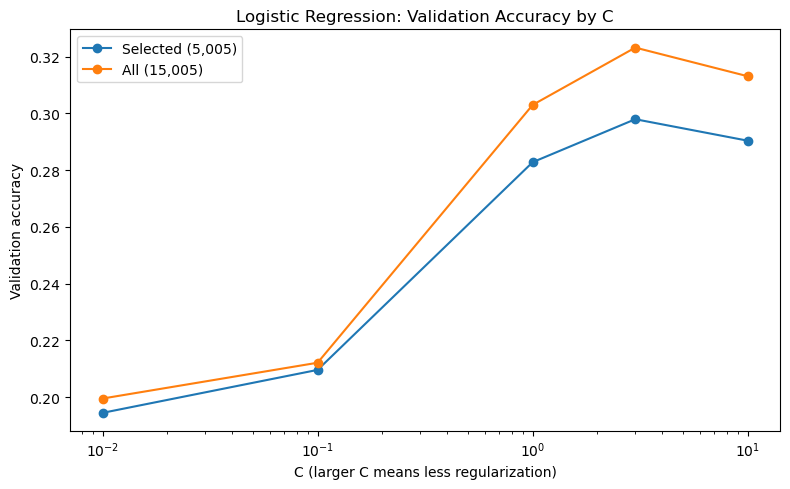

Chosen logistic regression: All (15,005) with C = 3.0
Training accuracy: 0.996 | Validation accuracy: 0.323


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Chance accuracy if every passage were assigned to one of the 18 LLMs at random
print("Chance accuracy:", round(1 / len(label_encoder.classes_), 3))

# C is the inverse of the L2 penalty. A larger C fits the training passages more closely.
# The test prompts stay unused until the final comparison.
C_values = [0.01, 0.1, 1, 3, 10]

logreg_matrices = {
    "Selected (5,005)": (X_train_selected, X_val_selected, X_test_selected),
    "All (15,005)": (X_train_all, X_val_all, X_test_all),
}

logreg_rows = []

for feature_name, (X_tr, X_va, X_te) in logreg_matrices.items():
    for C in C_values:
        model = LogisticRegression(
            C=C,
            solver="lbfgs",
            max_iter=800,
            random_state=42,
        )
        model.fit(X_tr, y_train)

        logreg_rows.append({
            "Features": feature_name,
            "C": C,
            "Training accuracy": accuracy_score(y_train, model.predict(X_tr)),
            "Validation accuracy": accuracy_score(y_val, model.predict(X_va)),
        })

logreg_results = pd.DataFrame(logreg_rows)
display(logreg_results.round(3))

plt.figure(figsize=(8, 5))

for feature_name, group in logreg_results.groupby("Features", sort=False):
    plt.plot(
        group["C"],
        group["Validation accuracy"],
        marker="o",
        label=feature_name,
    )

plt.xscale("log")
plt.xlabel("C (larger C means less regularization)")
plt.ylabel("Validation accuracy")
plt.title("Logistic Regression: Validation Accuracy by C")
plt.legend()
plt.tight_layout()
plt.show()

# If two settings tie on validation accuracy, keep the lower training accuracy.
best_logreg = (
    logreg_results
    .sort_values(["Validation accuracy", "Training accuracy"], ascending=[False, True])
    .iloc[0]
)

logreg_X_train, logreg_X_val, logreg_X_test = logreg_matrices[best_logreg["Features"]]

logreg_model = LogisticRegression(
    C=best_logreg["C"],
    solver="lbfgs",
    max_iter=800,
    random_state=42,
)
logreg_model.fit(logreg_X_train, y_train)

print(
    "Chosen logistic regression:",
    best_logreg["Features"],
    "with C =",
    best_logreg["C"],
)
print(
    "Training accuracy:",
    round(best_logreg["Training accuracy"], 3),
    "| Validation accuracy:",
    round(best_logreg["Validation accuracy"], 3),
)

The best validation accuracy is 0.321, from the full 15,005 features with C = 3. That is well above the 0.056 chance level. Training accuracy at that setting is 0.996, so the model still memorizes most of the training passages. Smaller values of C shrink that gap, but validation accuracy drops with them. The 5,005 selected features stay a little below the full set at every C we tried. We keep the full feature set and C = 3.

## 8. Linear Support Vector Machine

A linear support vector machine also learns one weight vector per LLM, but it places the boundary to maximize the margin between classes. `LinearSVC` trains a separate binary classifier for each LLM. There are more features than training passages, so we use the dual formulation. We tune `C` on the same two feature sets and again leave the test prompts untouched.

,Features,C,Training accuracy,Validation accuracy
0,"Selected (5,005)",0.01,0.356,0.205
1,"Selected (5,005)",0.10,0.907,0.285
2,"Selected (5,005)",0.30,0.995,0.308
3,"Selected (5,005)",1.00,1.000,0.288
4,"Selected (5,005)",3.00,1.000,0.273
5,"All (15,005)",0.01,0.513,0.227
6,"All (15,005)",0.10,0.989,0.311
7,"All (15,005)",0.30,1.000,0.316
8,"All (15,005)",1.00,1.000,0.295
9,"All (15,005)",3.00,1.000,0.285


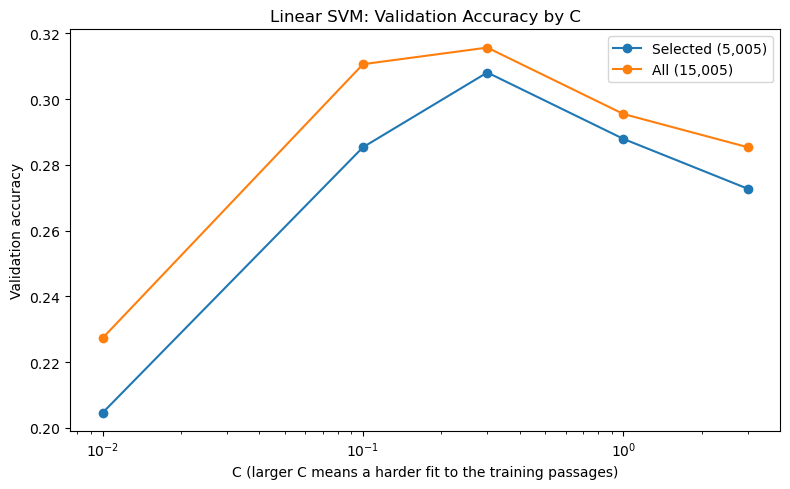

Chosen linear SVM: All (15,005) with C = 0.3
Training accuracy: 1.0 | Validation accuracy: 0.316


In [17]:
from sklearn.svm import LinearSVC

# C controls the penalty on points that fall inside the margin.
C_values = [0.01, 0.1, 0.3, 1, 3]

svm_matrices = {
    "Selected (5,005)": (X_train_selected, X_val_selected, X_test_selected),
    "All (15,005)": (X_train_all, X_val_all, X_test_all),
}

svm_rows = []

for feature_name, (X_tr, X_va, X_te) in svm_matrices.items():
    for C in C_values:
        model = LinearSVC(
            C=C,
            dual=True,
            max_iter=4000,
            random_state=42,
        )
        model.fit(X_tr, y_train)

        svm_rows.append({
            "Features": feature_name,
            "C": C,
            "Training accuracy": accuracy_score(y_train, model.predict(X_tr)),
            "Validation accuracy": accuracy_score(y_val, model.predict(X_va)),
        })

svm_results = pd.DataFrame(svm_rows)
display(svm_results.round(3))

plt.figure(figsize=(8, 5))

for feature_name, group in svm_results.groupby("Features", sort=False):
    plt.plot(
        group["C"],
        group["Validation accuracy"],
        marker="o",
        label=feature_name,
    )

plt.xscale("log")
plt.xlabel("C (larger C means a harder fit to the training passages)")
plt.ylabel("Validation accuracy")
plt.title("Linear SVM: Validation Accuracy by C")
plt.legend()
plt.tight_layout()
plt.show()

best_svm = (
    svm_results
    .sort_values(["Validation accuracy", "Training accuracy"], ascending=[False, True])
    .iloc[0]
)

svm_X_train, svm_X_val, svm_X_test = svm_matrices[best_svm["Features"]]

svm_model = LinearSVC(
    C=best_svm["C"],
    dual=True,
    max_iter=4000,
    random_state=42,
)
svm_model.fit(svm_X_train, y_train)

print(
    "Chosen linear SVM:",
    best_svm["Features"],
    "with C =",
    best_svm["C"],
)
print(
    "Training accuracy:",
    round(best_svm["Training accuracy"], 3),
    "| Validation accuracy:",
    round(best_svm["Validation accuracy"], 3),
)

The best validation accuracy is 0.318, from the full 15,005 features with C = 0.3. That is almost the same as logistic regression. Training accuracy is 1.000, so the margin is fit tightly to the training passages. Larger values of C do not improve the validation set, and the reduced feature set stays slightly behind the full set. We keep the full 15,005 features and C = 0.3.

## 9A. Historical scikit-learn MLP experiments (exploratory baseline — not the final MLP)

The following team's existing experiments are preserved so we can compare an earlier one-layer solution with a compliant deep-learning implementation. The strongest historical configuration used just one hidden layer and `sklearn.neural_network.MLPClassifier`, which is **not sufficient** for the assigned TensorFlow/Keras or PyTorch MLP requirement. The required final model is in Section 9B.


The multilayer perceptron adds a hidden layer with ReLU activations, so it can combine word, character, and style features instead of treating each one on its own. The training set has 1,890 passages and thousands of features, so a large network can memorize the training text. We start with one hidden layer of 64 units, then try a wider layer, stronger L2 regularization (`alpha`), and one two-layer network.

Adam's learning rate stays at 0.001, and each update uses a mini-batch of 64 passages. sklearn can stop training with its own validation split, but that split is random rows and can put two answers to the same prompt on opposite sides. We train one epoch at a time and keep the epoch with the best accuracy on the prompt-level validation set. Architectures are compared on the 5,005 selected features, and the winner is then trained again on the full feature set.

**Interpretation note:** The numbers in this subsection are **validation** results for the historical scikit-learn network. They must not be reported as the final Keras MLP test results.


In [18]:
import copy
import warnings

from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier

# The MLP trains on dense arrays, so convert each feature matrix once.
mlp_matrices = {
    "Selected (5,005)": (
        X_train_selected.toarray(),
        X_val_selected.toarray(),
        X_test_selected.toarray(),
    ),
    "All (15,005)": (
        X_train_all.toarray(),
        X_val_all.toarray(),
        X_test_all.toarray(),
    ),
}

def train_mlp(X_train, y_train, X_val, y_val, hidden_layer_sizes, alpha, max_epochs=30):
    mlp = MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation="relu",
        solver="adam",
        alpha=alpha,
        batch_size=64,
        learning_rate_init=0.001,
        max_iter=1,
        warm_start=True,
        random_state=42,
        tol=0,
    )

    history = []
    best_model = None
    best_val = -1

    for epoch in range(1, max_epochs + 1):
        # max_iter is 1 on purpose, so ignore the warning that training has not converged yet.
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            mlp.fit(X_train, y_train)

        train_acc = accuracy_score(y_train, mlp.predict(X_train))
        val_acc = accuracy_score(y_val, mlp.predict(X_val))

        history.append({
            "Epoch": epoch,
            "Training loss": float(mlp.loss_),
            "Training accuracy": train_acc,
            "Validation accuracy": val_acc,
        })

        if val_acc > best_val:
            best_val = val_acc
            best_model = copy.deepcopy(mlp)

    return best_model, pd.DataFrame(history)

mlp_configs = [
    ((64,), 0.0001),
    ((128,), 0.0001),
    ((128,), 0.001),
    ((128,), 0.01),
    ((256,), 0.001),
    ((128, 64), 0.001),
]

X_tr, X_va, X_te = mlp_matrices["Selected (5,005)"]
mlp_runs = []

for hidden_layer_sizes, alpha in mlp_configs:
    model, history = train_mlp(
        X_tr, y_train, X_va, y_val, hidden_layer_sizes, alpha
    )
    best = history.loc[history["Validation accuracy"].idxmax()]

    mlp_runs.append({
        "Features": "Selected (5,005)",
        "Hidden layers": hidden_layer_sizes,
        "Alpha": alpha,
        "Best epoch": int(best["Epoch"]),
        "Training accuracy": best["Training accuracy"],
        "Validation accuracy": best["Validation accuracy"],
        "model": model,
        "history": history,
    })

mlp_search = pd.DataFrame([
    {
        "Hidden layers": ", ".join(str(size) for size in run["Hidden layers"]),
        "Alpha": run["Alpha"],
        "Best epoch": run["Best epoch"],
        "Training accuracy": round(run["Training accuracy"], 3),
        "Validation accuracy": round(run["Validation accuracy"], 3),
    }
    for run in mlp_runs
])

display(mlp_search)

,Hidden layers,Alpha,Best epoch,Training accuracy,Validation accuracy
0,64,0.0001,15,0.849,0.308
1,128,0.0001,17,0.943,0.328
2,128,0.0010,18,0.942,0.338
3,128,0.0100,22,0.942,0.341
4,256,0.0010,22,0.981,0.318
5,"128, 64",0.0010,19,0.973,0.308


,Features,Hidden layers,Alpha,Best epoch,Training accuracy,Validation accuracy
0,"Selected (5,005)",128,0.01,22,0.942,0.341
1,"All (15,005)",128,0.01,13,0.954,0.331


Chosen MLP: Selected (5,005) | hidden layers = (128,) | alpha = 0.01 | epoch = 22
Training accuracy: 0.942 | Validation accuracy: 0.341


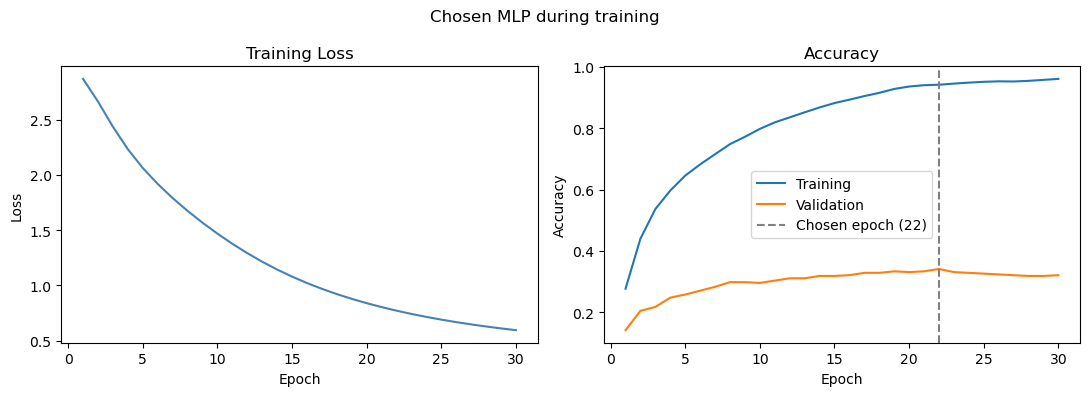

In [19]:
# Keep the selected-feature run with the best validation accuracy.
# If two runs tie, keep the one with the lower training accuracy.
best_run = sorted(
    mlp_runs,
    key=lambda run: (run["Validation accuracy"], -run["Training accuracy"]),
    reverse=True,
)[0]

# Train that same architecture on the full feature set.
X_tr, X_va, X_te = mlp_matrices["All (15,005)"]
model_all, history_all = train_mlp(
    X_tr,
    y_train,
    X_va,
    y_val,
    best_run["Hidden layers"],
    best_run["Alpha"],
)
best_all = history_all.loc[history_all["Validation accuracy"].idxmax()]

mlp_comparison = pd.DataFrame([
    {
        "Features": "Selected (5,005)",
        "Hidden layers": ", ".join(str(size) for size in best_run["Hidden layers"]),
        "Alpha": best_run["Alpha"],
        "Best epoch": best_run["Best epoch"],
        "Training accuracy": round(best_run["Training accuracy"], 3),
        "Validation accuracy": round(best_run["Validation accuracy"], 3),
    },
    {
        "Features": "All (15,005)",
        "Hidden layers": ", ".join(str(size) for size in best_run["Hidden layers"]),
        "Alpha": best_run["Alpha"],
        "Best epoch": int(best_all["Epoch"]),
        "Training accuracy": round(best_all["Training accuracy"], 3),
        "Validation accuracy": round(best_all["Validation accuracy"], 3),
    },
])

display(mlp_comparison)

if best_all["Validation accuracy"] > best_run["Validation accuracy"]:
    chosen_name = "All (15,005)"
    mlp_model = model_all
    mlp_history = history_all
else:
    chosen_name = "Selected (5,005)"
    mlp_model = best_run["model"]
    mlp_history = best_run["history"]

mlp_X_train, mlp_X_val, mlp_X_test = mlp_matrices[chosen_name]
chosen_epoch = int(mlp_history.loc[mlp_history["Validation accuracy"].idxmax(), "Epoch"])
chosen_row = mlp_history.loc[mlp_history["Validation accuracy"].idxmax()]

print(
    "Chosen MLP:",
    chosen_name,
    "| hidden layers =",
    best_run["Hidden layers"],
    "| alpha =",
    best_run["Alpha"],
    "| epoch =",
    chosen_epoch,
)
print(
    "Training accuracy:",
    round(chosen_row["Training accuracy"], 3),
    "| Validation accuracy:",
    round(chosen_row["Validation accuracy"], 3),
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(mlp_history["Epoch"], mlp_history["Training loss"], color="steelblue")
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[1].plot(mlp_history["Epoch"], mlp_history["Training accuracy"], label="Training")
axes[1].plot(mlp_history["Epoch"], mlp_history["Validation accuracy"], label="Validation")
axes[1].axvline(
    chosen_epoch,
    color="gray",
    linestyle="--",
    label=f"Chosen epoch ({chosen_epoch})",
)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

fig.suptitle("Chosen MLP during training")
fig.tight_layout()
plt.show()

On the selected 5,005-feature set, the strongest historical **scikit-learn** MLP used one hidden layer of **128 neurons**, L2 `alpha = 0.01`, and the weights selected at **epoch 22**. It achieved **0.341 validation accuracy** and **0.942 training accuracy** at that epoch. The same settings with all 15,005 features reached **0.331 validation accuracy** at epoch 13, with **0.954 training accuracy**. The sizeable gaps between training and validation accuracy suggest overfitting rather than reliable memorization-free generalization. The selected-feature run did better on validation for this exploratory MLP, but this does not establish that feature selection improved performance for the final Keras network.

The experiment also compared one-layer networks with 64 and 256 neurons and an exploratory two-layer 128/64 architecture. Among the reported selected-feature trials, the one-layer 128-neuron configuration with `alpha = 0.01` had the highest validation accuracy. These results were selected using the grouped validation set, not the held-out test set.

**Status:** Section 9A remains a **historical baseline** only. For the assignment's final neural network results, use the compliant two-hidden-layer Keras model in Section 9B and the held-out comparisons in Section 10B. Do not copy Section 10A's scikit-learn MLP scores into the final report.


## 9B. Final compliant neural network: Keras MLP

The final multilayer perceptron uses **two dense hidden layers (128 and 64 units)** with ReLU activations, dropout to reduce overfitting, and an **18-neuron softmax output**. The loss is sparse categorical cross-entropy, and the Adam optimizer uses a learning rate of **0.001**. Each batch contains **64 passages**; training can run for up to **35 epochs**, with early stopping monitoring **validation loss** (patience = 6, restored best weights). Two regularization configurations are compared separately for the **full 15,005-feature** and **selected 5,005-feature** inputs. Model selection uses validation macro-F1, then validation accuracy as the tiebreaker. The held-out test set is not accessed during training or configuration selection.

The neural network is implemented using **Keras 3**, preferring a **TensorFlow backend** when TensorFlow is installed; otherwise it uses a **PyTorch backend** if PyTorch is installed. Both routes use a Keras model with the architecture above, backed by a framework allowed in the project instructions. The backend, package versions, and hardware support are printed by the next cell. Results can vary slightly by backend and environment despite fixed seeds.

Training and validation sets contain answers to different `prompt_id` values. Unlike a random row-level internal validation split, this prevents the same prompt from appearing on both sides of the split. All preprocessing and chi-square feature selection were learned from training examples only.


In [20]:
# Section 9B: framework setup and reproducible Keras network builder.
# Install first: python -m pip install keras tensorflow  (or keras torch)
import os
import sys
import importlib.util
from pathlib import Path

# Keras backend must be chosen before importing keras in a fresh kernel.
if "keras" not in sys.modules:
    if importlib.util.find_spec("tensorflow") is not None:
        os.environ["KERAS_BACKEND"] = "tensorflow"
    elif importlib.util.find_spec("torch") is not None:
        os.environ["KERAS_BACKEND"] = "torch"
    else:
        raise ImportError("Install TensorFlow (preferred) or PyTorch, plus keras, then restart the kernel.")

import keras
from keras import layers, regularizers
from sklearn.metrics import f1_score, accuracy_score

SEED = 42
keras.utils.set_random_seed(SEED)
FEATURE_SETS = {
    "All (15,005)": (X_train_all, X_val_all, X_test_all),
    "Selected (5,005)": (X_train_selected, X_val_selected, X_test_selected),
}

# Convert each sparse matrix once. TF-IDF, style scaling, and chi-square selection
# have already been fitted ONLY on the training set in previous notebook sections.
keras_feature_sets = {
    label: tuple(m.toarray().astype(np.float32, copy=False) for m in matrices)
    for label, matrices in FEATURE_SETS.items()
}
assert len(label_encoder.classes_) == 18
assert np.array_equal(y_test, label_encoder.transform(test_df["model"]))
assert set(train_df["prompt_id"]).isdisjoint(val_df["prompt_id"])
assert set(train_df["prompt_id"]).isdisjoint(test_df["prompt_id"])
assert set(val_df["prompt_id"]).isdisjoint(test_df["prompt_id"])

print("Python:", sys.version.split()[0], "| Keras:", keras.__version__,
      "| backend:", keras.config.backend())
print("NumPy:", np.__version__, "| scikit-learn:", sklearn.__version__ if "sklearn" in globals() else "see Section 10")
if keras.config.backend() == "tensorflow":
    import tensorflow as tf
    print("TensorFlow:", tf.__version__, "| visible GPUs:", len(tf.config.list_physical_devices("GPU")))
else:
    import torch
    print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
for label, matrices in keras_feature_sets.items():
    print(label, ":", [m.shape for m in matrices])


def build_keras_mlp(input_features, dropout_rate=0.30, l2_strength=0.0003, learning_rate=0.001):
    network = keras.Sequential([
        keras.Input(shape=(input_features,)),
        layers.Dense(128, activation="relu",
                     kernel_regularizer=regularizers.l2(l2_strength)),
        layers.Dropout(dropout_rate),
        layers.Dense(64, activation="relu",
                     kernel_regularizer=regularizers.l2(l2_strength)),
        layers.Dropout(dropout_rate / 2),
        layers.Dense(len(label_encoder.classes_), activation="softmax"),
    ], name="name_that_llm_keras_mlp")
    network.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return network


Python: 3.13.9 | Keras: 3.15.1 | backend: tensorflow
NumPy: 2.3.5 | scikit-learn: 1.7.2
TensorFlow: 2.21.0 | visible GPUs: 0
All (15,005) : [(1890, 15005), (396, 15005), (413, 15005)]
Selected (5,005) : [(1890, 5005), (396, 5005), (413, 5005)]


In [21]:
# Section 9B: tune ONLY on grouped validation data. The test data remains untouched.
from IPython.display import display
import pandas as pd

KERAS_CONFIGS = [
    {"name": "128-64 / dropout 0.30", "dropout": 0.30, "l2": 0.0003, "learning_rate": 0.001},
    {"name": "128-64 / dropout 0.50", "dropout": 0.50, "l2": 0.0010, "learning_rate": 0.001},
]
KERAS_MAX_EPOCHS = 35
KERAS_BATCH_SIZE = 64
models_directory = Path("models")
models_directory.mkdir(exist_ok=True)

keras_trials = []
keras_winners = {}
for feature_name, (train_array, val_array, _unused_test) in keras_feature_sets.items():
    candidates = []
    for config in KERAS_CONFIGS:
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED)
        model = build_keras_mlp(train_array.shape[1],
            dropout_rate=config["dropout"],
            l2_strength=config["l2"],
            learning_rate=config["learning_rate"])
        early_stopping = keras.callbacks.EarlyStopping(
            monitor="val_loss", mode="min", patience=6, min_delta=0.001,
            restore_best_weights=True,
        )
        history = model.fit(
            train_array, y_train,
            validation_data=(val_array, y_val),
            epochs=KERAS_MAX_EPOCHS,
            batch_size=KERAS_BATCH_SIZE,
            callbacks=[early_stopping],
            verbose=0,
            shuffle=True,
        )
        val_pred = np.argmax(model.predict(val_array, batch_size=128, verbose=0), axis=1)
        validation_accuracy = accuracy_score(y_val, val_pred)
        validation_macro_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
        best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
        record = {
            "Feature set": feature_name,
            "Configuration": config["name"],
            "Dropout": config["dropout"],
            "L2": config["l2"],
            "Validation accuracy": float(validation_accuracy),
            "Validation macro F1": float(validation_macro_f1),
            "Epochs trained": len(history.history["loss"]),
            "Lowest validation loss epoch": best_epoch,
        }
        keras_trials.append(record)
        candidates.append({"record": record, "model": model, "history": history.history})
        print(feature_name, config["name"],
              "| epochs:", record["Epochs trained"],
              "| val accuracy:", f"{validation_accuracy:.3f}",
              "| val macro F1:", f"{validation_macro_f1:.3f}")

    # Best candidate for this feature set, chosen without ever using the test data.
    winner = max(candidates, key=lambda candidate: (
        candidate["record"]["Validation macro F1"],
        candidate["record"]["Validation accuracy"],
        -candidate["record"]["Epochs trained"],
    ))
    model_path = models_directory / ("mlp_all.keras" if feature_name.startswith("All") else "mlp_selected.keras")
    winner["model"].save(str(model_path))
    keras_winners[feature_name] = {
        "record": winner["record"],
        "history": winner["history"],
        "saved_model": str(model_path),
    }

keras_tuning_results = pd.DataFrame(keras_trials)
print("\nKeras tuning results (validation only):")
display(keras_tuning_results.round(3))
print("\nSaved winning Keras models:")
for features, details in keras_winners.items():
    print(features, "=>", details["saved_model"],
          "|", details["record"]["Configuration"])



All (15,005) 128-64 / dropout 0.30 | epochs: 12 | val accuracy: 0.298 | val macro F1: 0.279
All (15,005) 128-64 / dropout 0.50 | epochs: 15 | val accuracy: 0.306 | val macro F1: 0.286
Selected (5,005) 128-64 / dropout 0.30 | epochs: 14 | val accuracy: 0.273 | val macro F1: 0.253
Selected (5,005) 128-64 / dropout 0.50 | epochs: 17 | val accuracy: 0.273 | val macro F1: 0.253

Keras tuning results (validation only):


,Feature set,Configuration,Dropout,L2,Validation accuracy,Validation macro F1,Epochs trained,Lowest validation loss epoch
0,"All (15,005)",128-64 / dropout 0.30,0.3,0.000,0.298,0.279,12,6
1,"All (15,005)",128-64 / dropout 0.50,0.5,0.001,0.306,0.286,15,9
2,"Selected (5,005)",128-64 / dropout 0.30,0.3,0.000,0.273,0.253,14,8
3,"Selected (5,005)",128-64 / dropout 0.50,0.5,0.001,0.273,0.253,17,11



Saved winning Keras models:
All (15,005) => models\mlp_all.keras | 128-64 / dropout 0.50
Selected (5,005) => models\mlp_selected.keras | 128-64 / dropout 0.50


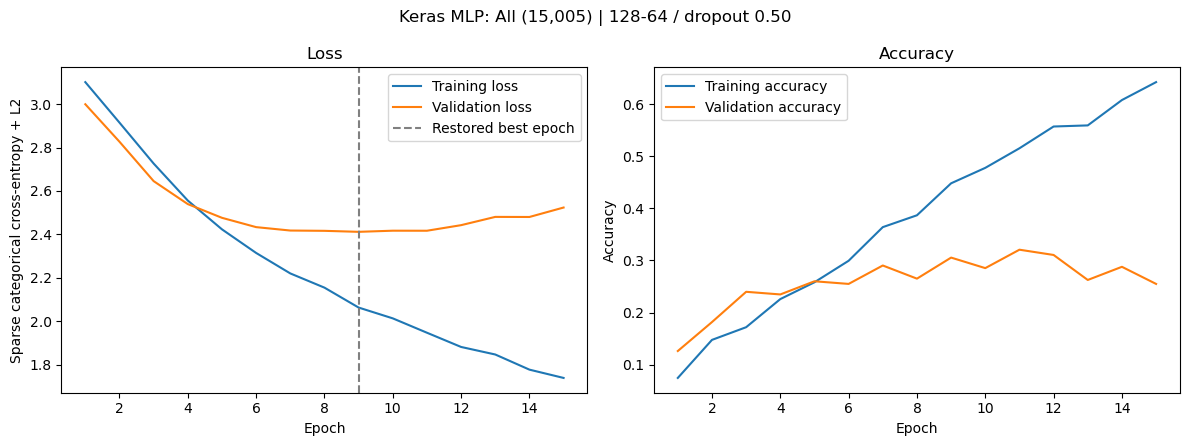

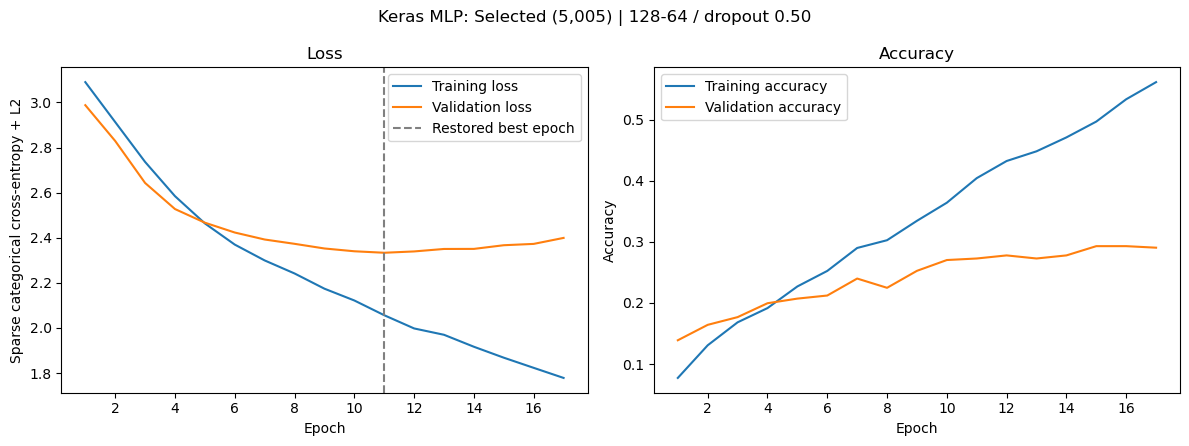

Curves saved in: C:\Users\Caden\Desktop\ARTI450-Name-That-LLM-main\figures


In [22]:
# Section 9B: required train/validation loss and accuracy curves for BOTH feature sets.
import matplotlib.pyplot as plt
figures_directory = Path("figures")
figures_directory.mkdir(exist_ok=True)

for feature_name, win in keras_winners.items():
    history = win["history"]
    epochs = np.arange(1, len(history["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(epochs, history["loss"], label="Training loss")
    axes[0].plot(epochs, history["val_loss"], label="Validation loss")
    axes[0].axvline(win["record"]["Lowest validation loss epoch"],
                    linestyle="--", color="gray", label="Restored best epoch")
    axes[0].set(xlabel="Epoch", ylabel="Sparse categorical cross-entropy + L2", title="Loss")
    axes[0].legend()
    axes[1].plot(epochs, history["accuracy"], label="Training accuracy")
    axes[1].plot(epochs, history["val_accuracy"], label="Validation accuracy")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
    axes[1].legend()
    fig.suptitle("Keras MLP: " + feature_name + " | " + win["record"]["Configuration"])
    fig.tight_layout()
    filename = "mlp_learning_curves_all.png" if feature_name.startswith("All") else "mlp_learning_curves_selected.png"
    fig.savefig(figures_directory / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Curves saved in:", figures_directory.resolve())


## 10A. Historical final evaluation from the team's existing scikit-learn notebook

The original code below is retained, including its six-row table and confusion matrices. **Its MLP rows use scikit-learn, not Keras**, so those MLP scores are **historical baselines only**. For the assigned final comparison and report, use the replacement Keras results in **Section 10B**. This prevents the older one-hidden-layer test metrics from being misrepresented as the compliant model's scores.


Python 3.13.9 | scikit-learn 1.7.2 | numpy 2.3.5 | pandas 2.3.3


,Classifier,Feature set,Accuracy,Macro precision,Macro recall,Macro F1
0,Logistic regression,"All (15,005)",0.334,0.315,0.333,0.315
2,Logistic regression,"Selected (5,005)",0.327,0.305,0.326,0.306
1,Linear SVM,"All (15,005)",0.356,0.334,0.355,0.334
3,Linear SVM,"Selected (5,005)",0.346,0.325,0.345,0.321
4,MLP,"All (15,005)",0.337,0.313,0.336,0.316
5,MLP,"Selected (5,005)",0.329,0.345,0.329,0.324


Logistic regression: accuracy change -0.007, macro F1 change -0.009
Linear SVM: accuracy change -0.010, macro F1 change -0.013
MLP: accuracy change -0.007, macro F1 change +0.009


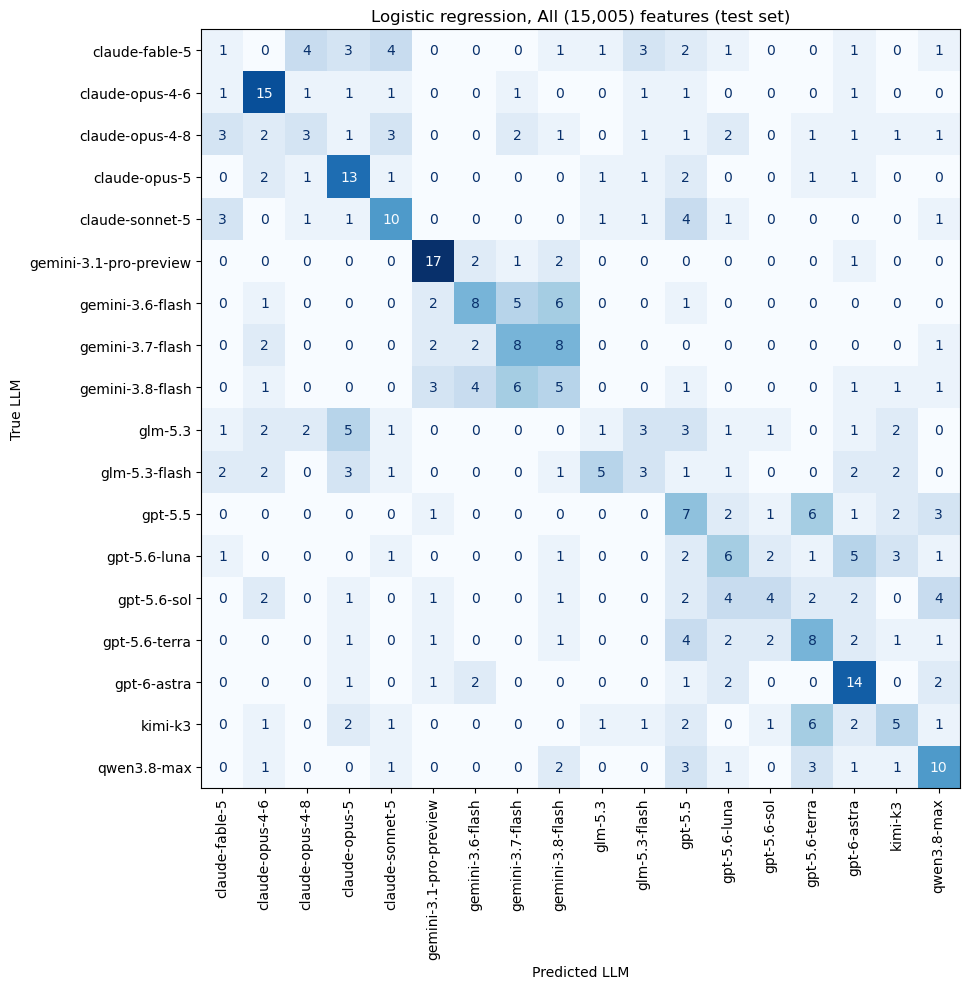

('Logistic regression', 'All (15,005)') top confusions:
   true gemini-3.7-flash -> predicted gemini-3.8-flash: 8
   true kimi-k3 -> predicted gpt-5.6-terra: 6
   true gemini-3.6-flash -> predicted gemini-3.8-flash: 6
   true gpt-5.5 -> predicted gpt-5.6-terra: 6
   true gemini-3.8-flash -> predicted gemini-3.7-flash: 6


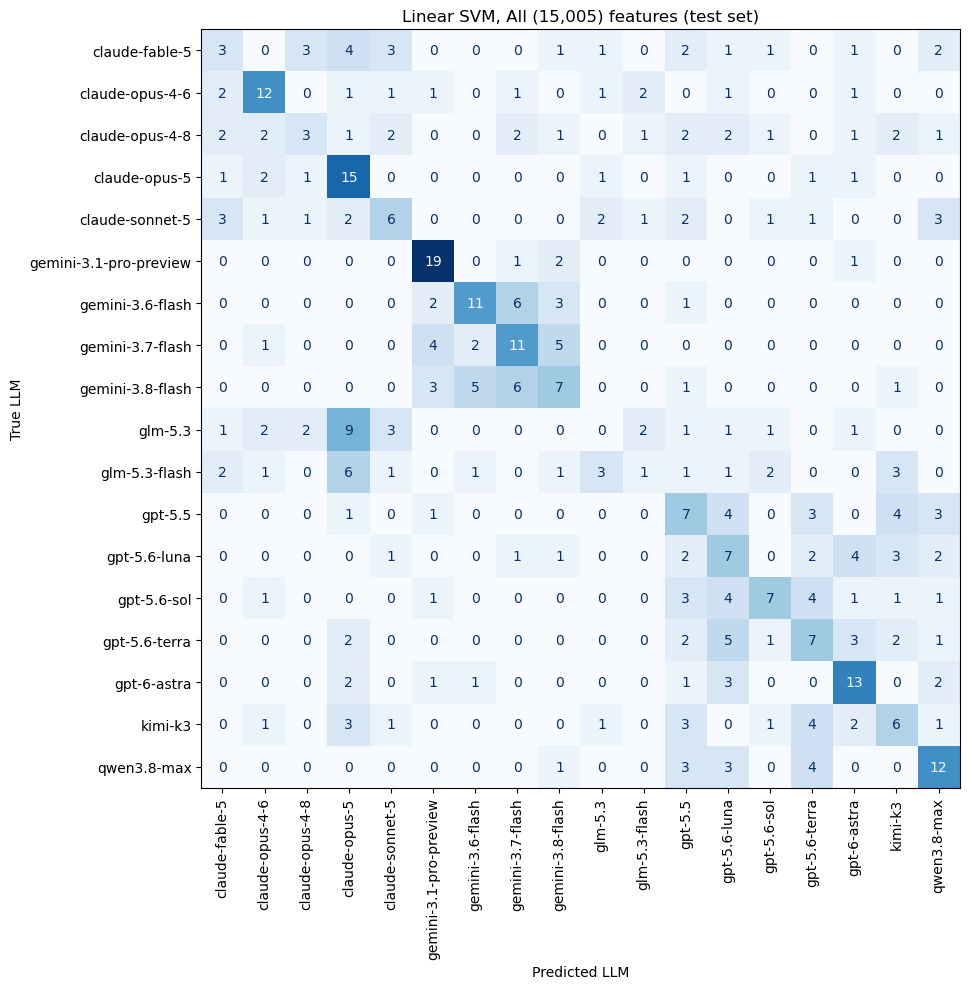

('Linear SVM', 'All (15,005)') top confusions:
   true glm-5.3 -> predicted claude-opus-5: 9
   true glm-5.3-flash -> predicted claude-opus-5: 6
   true gemini-3.8-flash -> predicted gemini-3.7-flash: 6
   true gemini-3.6-flash -> predicted gemini-3.7-flash: 6
   true gemini-3.8-flash -> predicted gemini-3.6-flash: 5


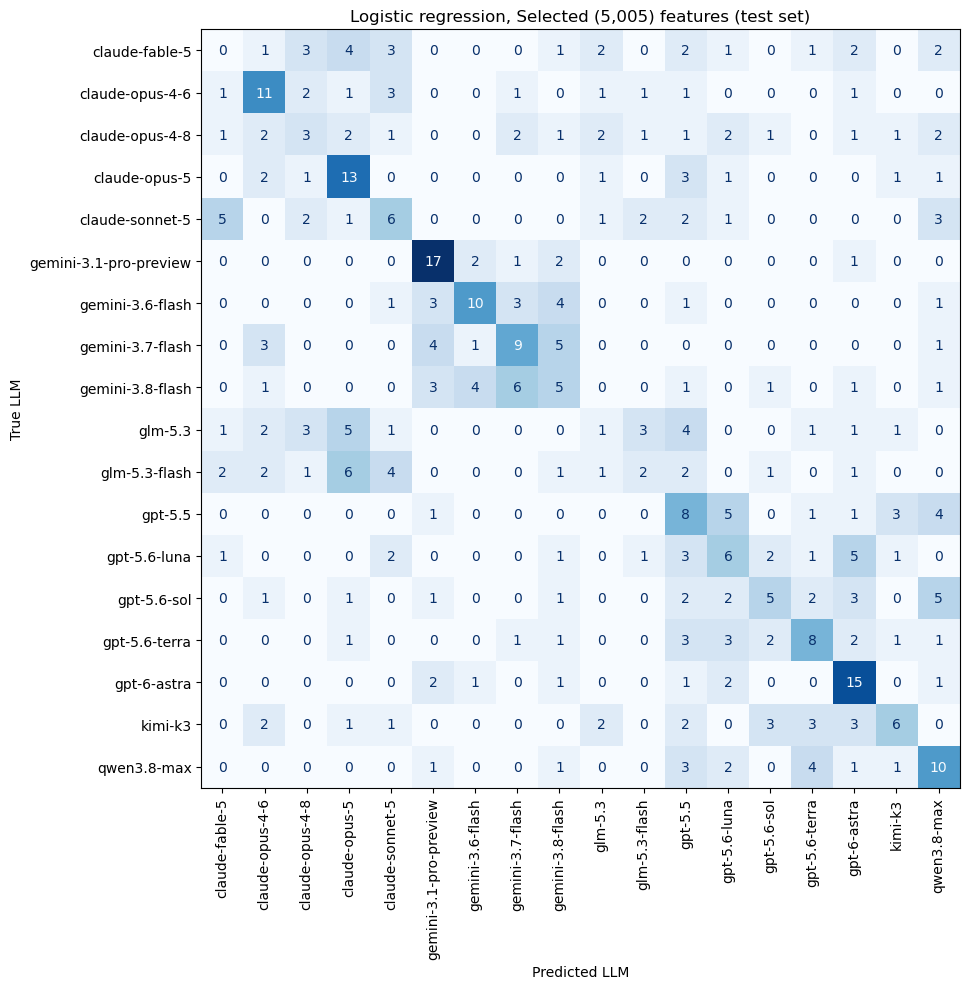

('Logistic regression', 'Selected (5,005)') top confusions:
   true glm-5.3-flash -> predicted claude-opus-5: 6
   true gemini-3.8-flash -> predicted gemini-3.7-flash: 6
   true gemini-3.7-flash -> predicted gemini-3.8-flash: 5
   true glm-5.3 -> predicted claude-opus-5: 5
   true gpt-5.6-sol -> predicted qwen3.8-max: 5


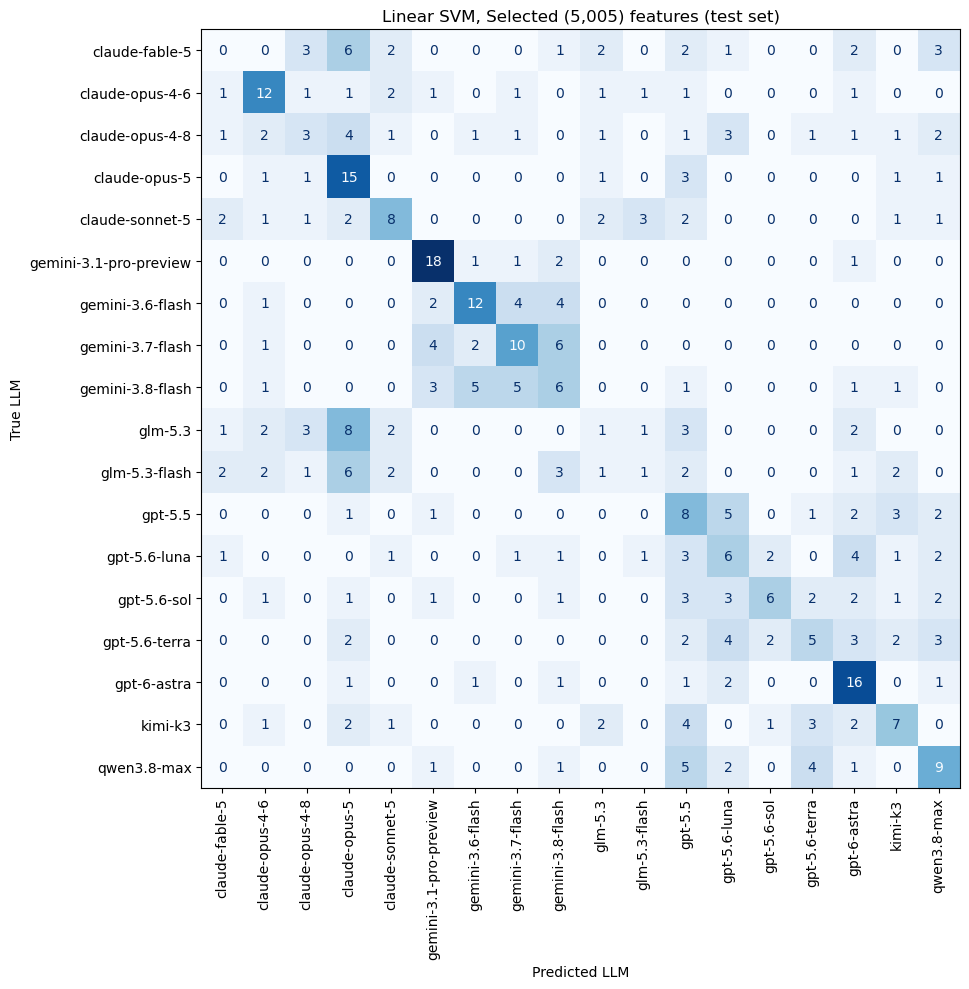

('Linear SVM', 'Selected (5,005)') top confusions:
   true glm-5.3 -> predicted claude-opus-5: 8
   true gemini-3.7-flash -> predicted gemini-3.8-flash: 6
   true claude-fable-5 -> predicted claude-opus-5: 6
   true glm-5.3-flash -> predicted claude-opus-5: 6
   true gemini-3.8-flash -> predicted gemini-3.6-flash: 5


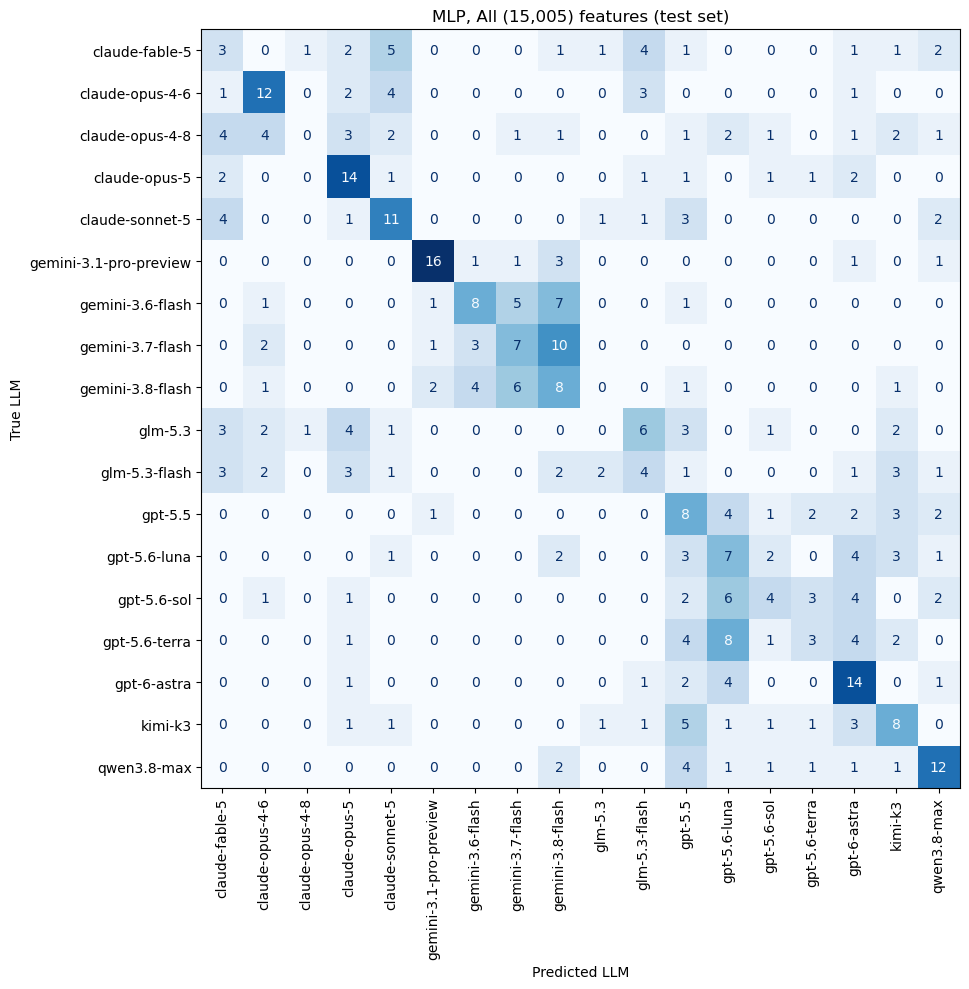

('MLP', 'All (15,005)') top confusions:
   true gemini-3.7-flash -> predicted gemini-3.8-flash: 10
   true gpt-5.6-terra -> predicted gpt-5.6-luna: 8
   true gemini-3.6-flash -> predicted gemini-3.8-flash: 7
   true glm-5.3 -> predicted glm-5.3-flash: 6
   true gemini-3.8-flash -> predicted gemini-3.7-flash: 6


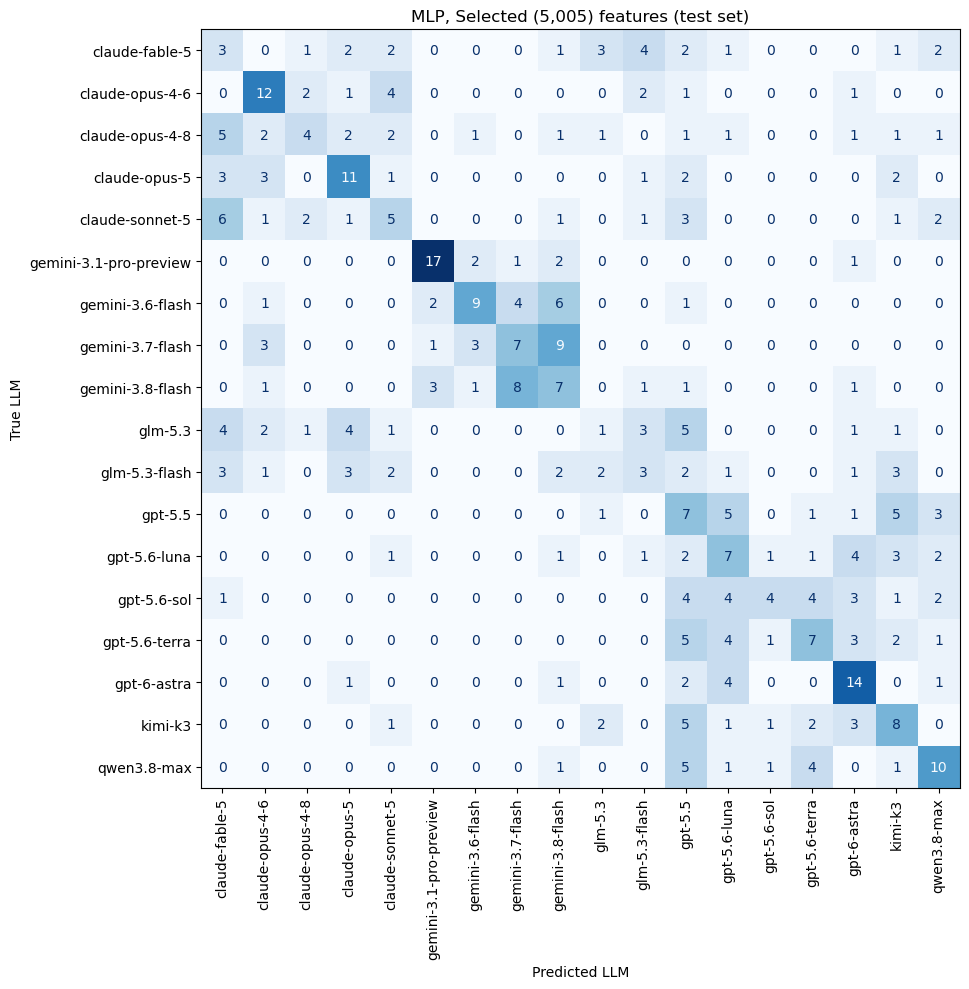

('MLP', 'Selected (5,005)') top confusions:
   true gemini-3.7-flash -> predicted gemini-3.8-flash: 9
   true gemini-3.8-flash -> predicted gemini-3.7-flash: 8
   true gemini-3.6-flash -> predicted gemini-3.8-flash: 6
   true claude-sonnet-5 -> predicted claude-fable-5: 6
   true kimi-k3 -> predicted gpt-5.5: 5


In [23]:
import sys
import sklearn
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__)

def best_C(results, feats):
    rows = results[results["Features"] == feats]
    return rows.sort_values(["Validation accuracy", "Training accuracy"],
                            ascending=[False, True]).iloc[0]["C"]

final_models = {}
for feats in ["All (15,005)", "Selected (5,005)"]:
    X_tr, X_va, X_te = logreg_matrices[feats]
    lr = LogisticRegression(C=best_C(logreg_results, feats), solver="lbfgs",
                            max_iter=800, random_state=42).fit(X_tr, y_train)
    svm = LinearSVC(C=best_C(svm_results, feats), dual=True,
                    max_iter=4000, random_state=42).fit(X_tr, y_train)
    final_models[("Logistic regression", feats)] = (lr, X_te)
    final_models[("Linear SVM", feats)] = (svm, X_te)

final_models[("MLP", "All (15,005)")] = (model_all, mlp_matrices["All (15,005)"][2])
final_models[("MLP", "Selected (5,005)")] = (best_run["model"], mlp_matrices["Selected (5,005)"][2])

rows, preds = [], {}
for (name, feats), (model, X_te) in final_models.items():
    pred = model.predict(X_te)
    preds[(name, feats)] = pred
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    rows.append({"Classifier": name, "Feature set": feats,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Macro precision": p, "Macro recall": r, "Macro F1": f})

test_results = pd.DataFrame(rows)
order = {"Logistic regression": 0, "Linear SVM": 1, "MLP": 2}
test_results = test_results.sort_values(["Classifier", "Feature set"],
                                        key=lambda s: s.map(order) if s.name == "Classifier" else s)
display(test_results.round(3))

# Change from feature selection (Selected minus All) for each model
for name in order:
    a = test_results[(test_results.Classifier == name) & (test_results["Feature set"] == "All (15,005)")].iloc[0]
    s = test_results[(test_results.Classifier == name) & (test_results["Feature set"] == "Selected (5,005)")].iloc[0]
    print(f"{name}: accuracy change {s.Accuracy - a.Accuracy:+.3f}, macro F1 change {s['Macro F1'] - a['Macro F1']:+.3f}")

# Confusion matrices and most common confusions
labels = label_encoder.classes_
for key, pred in preds.items():
    cm = confusion_matrix(y_test, pred, labels=range(len(labels)))
    fig, ax = plt.subplots(figsize=(10, 10))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, xticks_rotation=90,
                                                           colorbar=False, cmap="Blues")
    ax.set_title(f"{key[0]}, {key[1]} features (test set)")
    ax.set_xlabel("Predicted LLM"); ax.set_ylabel("True LLM")
    plt.tight_layout(); plt.show()

    off = cm.copy(); np.fill_diagonal(off, 0)
    top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:5], off.shape))[0]
    print(key, "top confusions:")
    for t, p_ in top:
        print(f"   true {labels[t]} -> predicted {labels[p_]}: {off[t, p_]}")

## 10B. Final required comparison: Keras MLP vs. Logistic Regression vs. Linear SVM

**Evaluation protocol.** All three classifiers use the *same* 413 labeled, prompt-disjoint held-out test passages. The full and chi-square-selected feature sets are both evaluated, giving **six rows** in the final comparison table. Regularization `C` for each traditional classifier/feature set was selected from the validation results in Sections 7 and 8. The best Keras architecture for each feature set was selected solely by grouped validation macro-F1 in Section 9B; trained weights are restored from the lowest validation-loss epoch. No test data were used to tune models.

The reported metrics are accuracy and **macro-averaged precision, recall, and F1**, which give each of the 18 LLM classes equal weight. Confusion matrices have the true LLM on the vertical axis and the predicted LLM on the horizontal axis. This final comparison supersedes the historical scikit-learn MLP results above. The Kaggle `test.csv` is unlabeled and is **not** the held-out test set used here.


In [24]:
# Section 10B: test set is accessed for FINAL evaluation only, AFTER all tuning.
import sklearn
import platform
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

print("Environment: Python", platform.python_version(),
      "| scikit-learn", sklearn.__version__,
      "| Keras", keras.__version__, "| backend", keras.config.backend())
print("Test passages:", len(y_test), "| test prompts:", test_df["prompt_id"].nunique())


def tuned_c_for_feature_set(table, feature_name):
    rows = table.loc[table["Features"] == feature_name]
    best_row = rows.sort_values(["Validation accuracy", "Training accuracy"],
                                ascending=[False, True]).iloc[0]
    return float(best_row["C"])

final_predictions = {}
final_metrics = []
for feature_name in ["All (15,005)", "Selected (5,005)"]:
    X_train_sparse, _X_val_sparse, X_test_sparse = FEATURE_SETS[feature_name]

    c_lr = tuned_c_for_feature_set(logreg_results, feature_name)
    lr = LogisticRegression(C=c_lr, solver="lbfgs", max_iter=800,
                            random_state=42).fit(X_train_sparse, y_train)
    final_predictions[("Logistic Regression", feature_name)] = lr.predict(X_test_sparse)

    c_svm = tuned_c_for_feature_set(svm_results, feature_name)
    svm = LinearSVC(C=c_svm, dual=True, max_iter=4000,
                    random_state=42).fit(X_train_sparse, y_train)
    final_predictions[("Linear SVM", feature_name)] = svm.predict(X_test_sparse)

    # Read the validation-selected Keras model; inference only on the held-out test set.
    keras_model = keras.models.load_model(keras_winners[feature_name]["saved_model"])
    test_array = keras_feature_sets[feature_name][2]
    mlp_probabilities = keras_model.predict(test_array, batch_size=128, verbose=0)
    final_predictions[("Keras MLP", feature_name)] = np.argmax(mlp_probabilities, axis=1)

for (classifier, feature_name), pred in final_predictions.items():
    final_metrics.append({
        "Classifier": classifier,
        "Feature set": feature_name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Macro recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
    })

final_test_results = pd.DataFrame(final_metrics)
classification_order = ["Logistic Regression", "Linear SVM", "Keras MLP"]
feature_order = ["All (15,005)", "Selected (5,005)"]
final_test_results["_classifier_order"] = pd.Categorical(
    final_test_results["Classifier"], categories=classification_order, ordered=True)
final_test_results["_feature_order"] = pd.Categorical(
    final_test_results["Feature set"], categories=feature_order, ordered=True)
final_test_results = (final_test_results.sort_values(["_classifier_order", "_feature_order"])
                      .drop(columns=["_classifier_order", "_feature_order"])
                      .reset_index(drop=True))

print("FINAL HELD-OUT TEST SCORES (all rows use the same 413 passages):")
display(final_test_results.round(3))
final_test_results.to_csv("final_test_results.csv", index=False)

feature_deltas = []
for classifier in classification_order:
    group = final_test_results.loc[final_test_results["Classifier"] == classifier]
    full = group.loc[group["Feature set"] == "All (15,005)"].iloc[0]
    selected = group.loc[group["Feature set"] == "Selected (5,005)"].iloc[0]
    feature_deltas.append({
        "Classifier": classifier,
        "Selected minus full accuracy": selected["Accuracy"] - full["Accuracy"],
        "Selected minus full macro F1": selected["Macro F1"] - full["Macro F1"],
    })
feature_selection_effects = pd.DataFrame(feature_deltas)
print("\nEffect of chi-square selection (positive = selected did better):")
display(feature_selection_effects.round(3))
feature_selection_effects.to_csv("feature_selection_effects.csv", index=False)


Environment: Python 3.13.9 | scikit-learn 1.7.2 | Keras 3.15.1 | backend tensorflow
Test passages: 413 | test prompts: 23
FINAL HELD-OUT TEST SCORES (all rows use the same 413 passages):


,Classifier,Feature set,Accuracy,Macro precision,Macro recall,Macro F1
0,Logistic Regression,"All (15,005)",0.334,0.315,0.333,0.315
1,Logistic Regression,"Selected (5,005)",0.327,0.305,0.326,0.306
2,Linear SVM,"All (15,005)",0.356,0.334,0.355,0.334
3,Linear SVM,"Selected (5,005)",0.346,0.325,0.345,0.321
4,Keras MLP,"All (15,005)",0.322,0.316,0.322,0.300
5,Keras MLP,"Selected (5,005)",0.310,0.311,0.309,0.284



Effect of chi-square selection (positive = selected did better):


,Classifier,Selected minus full accuracy,Selected minus full macro F1
0,Logistic Regression,-0.007,-0.009
1,Linear SVM,-0.010,-0.013
2,Keras MLP,-0.012,-0.016


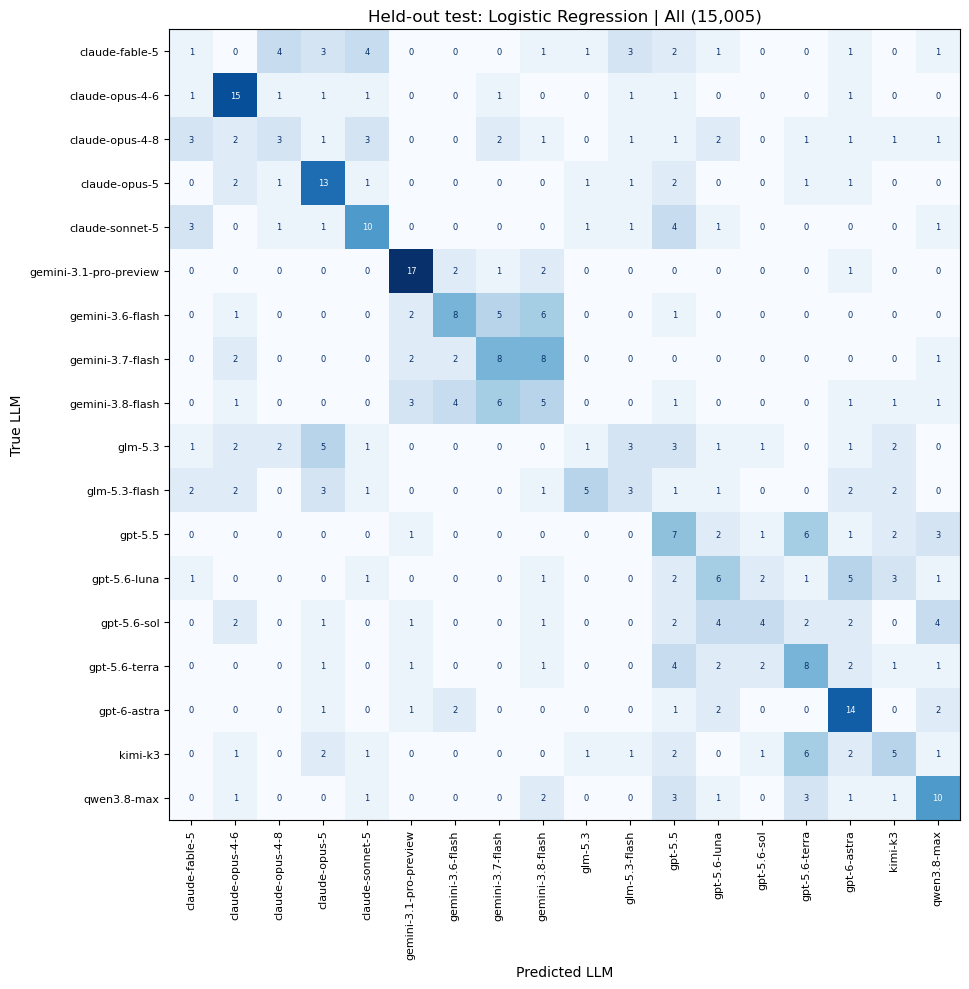

Logistic Regression | All (15,005) — largest off-diagonal confusions:
  gemini-3.7-flash -> gemini-3.8-flash: 8 passages
  kimi-k3 -> gpt-5.6-terra: 6 passages
  gpt-5.5 -> gpt-5.6-terra: 6 passages
  gemini-3.8-flash -> gemini-3.7-flash: 6 passages
  gemini-3.6-flash -> gemini-3.8-flash: 6 passages


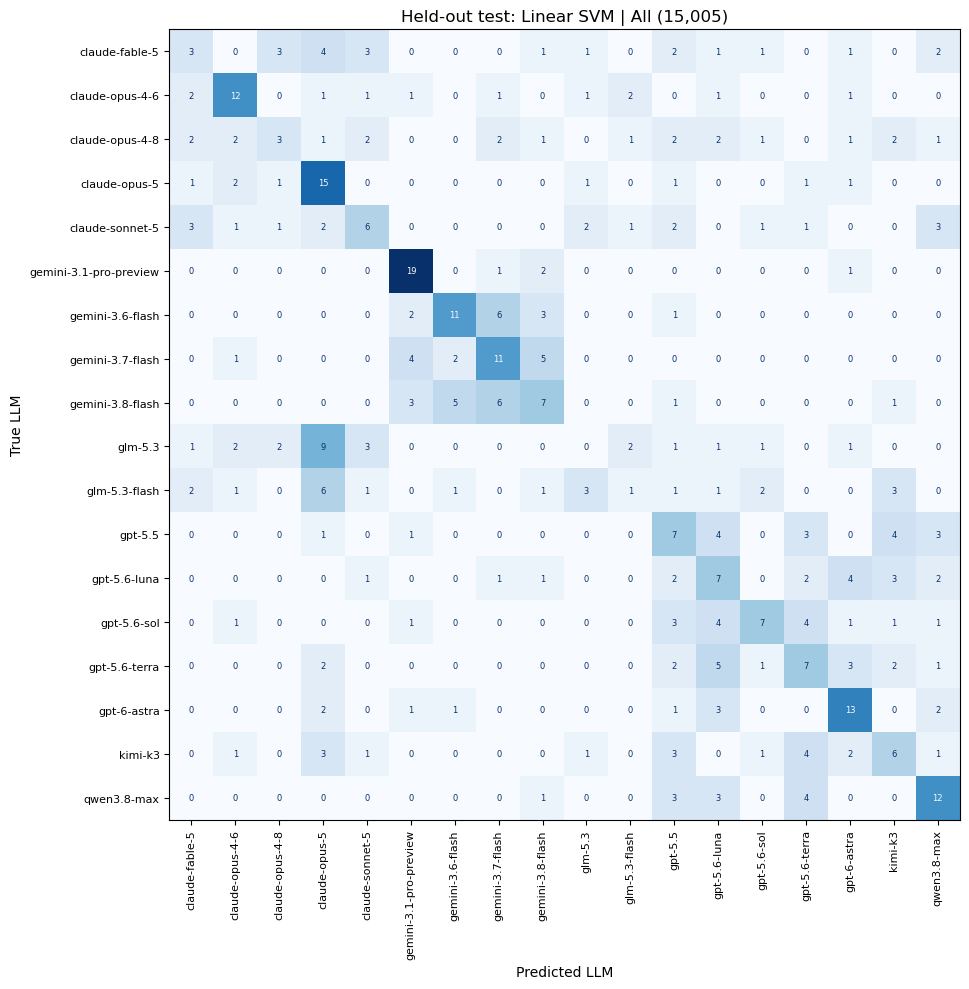

Linear SVM | All (15,005) — largest off-diagonal confusions:
  glm-5.3 -> claude-opus-5: 9 passages
  glm-5.3-flash -> claude-opus-5: 6 passages
  gemini-3.8-flash -> gemini-3.7-flash: 6 passages
  gemini-3.6-flash -> gemini-3.7-flash: 6 passages
  gpt-5.6-terra -> gpt-5.6-luna: 5 passages


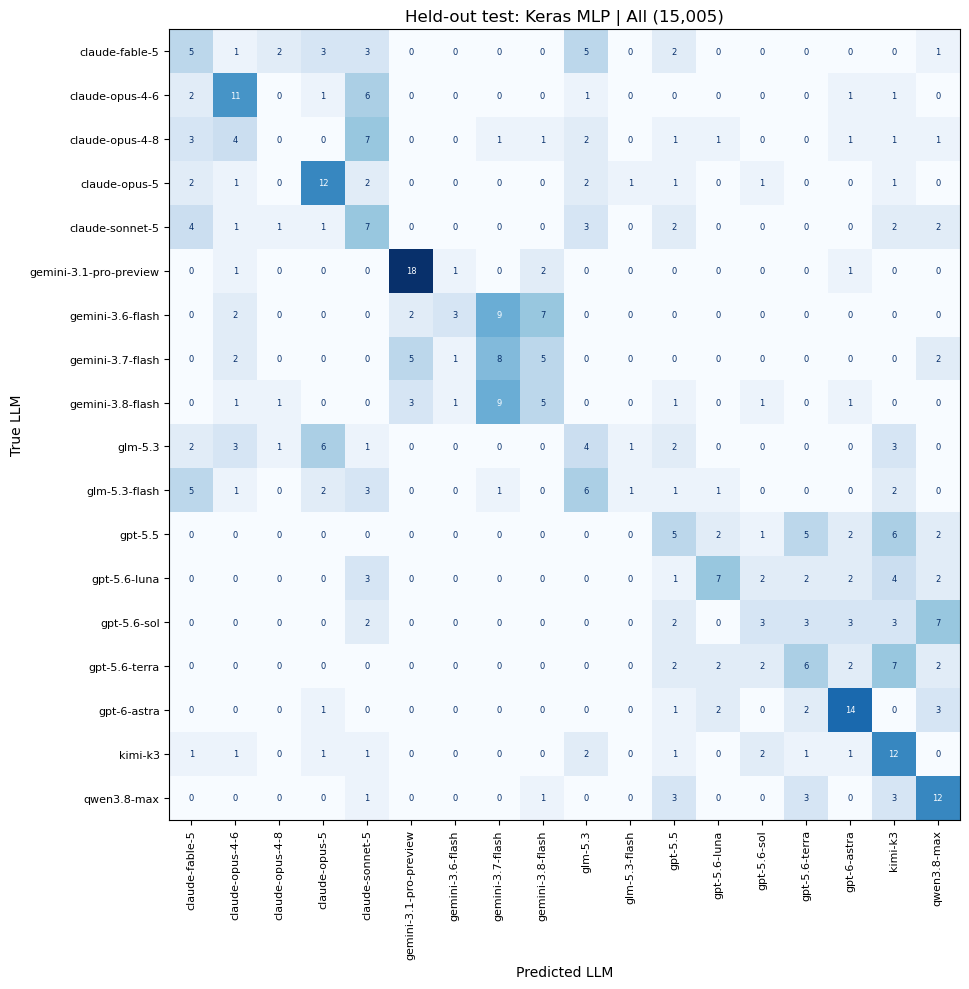

Keras MLP | All (15,005) — largest off-diagonal confusions:
  gemini-3.8-flash -> gemini-3.7-flash: 9 passages
  gemini-3.6-flash -> gemini-3.7-flash: 9 passages
  gpt-5.6-terra -> kimi-k3: 7 passages
  gpt-5.6-sol -> qwen3.8-max: 7 passages
  gemini-3.6-flash -> gemini-3.8-flash: 7 passages
Logistic Regression | Selected (5,005) — largest off-diagonal confusions:
  glm-5.3-flash -> claude-opus-5: 6 passages
  gemini-3.8-flash -> gemini-3.7-flash: 6 passages
  gpt-5.6-sol -> qwen3.8-max: 5 passages
  gpt-5.6-luna -> gpt-6-astra: 5 passages
  gpt-5.5 -> gpt-5.6-luna: 5 passages
Linear SVM | Selected (5,005) — largest off-diagonal confusions:
  glm-5.3 -> claude-opus-5: 8 passages
  glm-5.3-flash -> claude-opus-5: 6 passages
  gemini-3.7-flash -> gemini-3.8-flash: 6 passages
  claude-fable-5 -> claude-opus-5: 6 passages
  qwen3.8-max -> gpt-5.5: 5 passages
Keras MLP | Selected (5,005) — largest off-diagonal confusions:
  gemini-3.6-flash -> gemini-3.7-flash: 9 passages
  gpt-5.6-sol -> q

In [25]:
# Section 10B: readable confusion matrices for every model and feature set.
# All six files are saved. The notebook displays the three highest-validation
# configurations (one from each classifier family) to avoid six giant plots.
from IPython.display import display

label_names = list(label_encoder.classes_)
selected_display_keys = {}
for classifier in classification_order:
    if classifier == "Keras MLP":
        chosen_set = max(feature_order, key=lambda features: (
            keras_winners[features]["record"]["Validation macro F1"],
            keras_winners[features]["record"]["Validation accuracy"],
        ))
    else:
        table = logreg_results if classifier == "Logistic Regression" else svm_results
        rows = []
        for feats in feature_order:
            eligible = table.loc[table["Features"] == feats]
            winner = eligible.sort_values(["Validation accuracy", "Training accuracy"],
                                          ascending=[False, True]).iloc[0]
            rows.append((float(winner["Validation accuracy"]), feats))
        chosen_set = max(rows)[1]
    selected_display_keys[classifier] = (classifier, chosen_set)

common_confusions = {}
for (classifier, feature_name), pred in final_predictions.items():
    cm = confusion_matrix(y_test, pred, labels=np.arange(len(label_names)))
    fig, ax = plt.subplots(figsize=(12, 10))
    show = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
    show.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False,
              values_format="d", text_kw={"fontsize": 6})
    ax.set_title(f"Held-out test: {classifier} | {feature_name}")
    ax.set_xlabel("Predicted LLM")
    ax.set_ylabel("True LLM")
    ax.tick_params(axis="both", labelsize=8)
    fig.tight_layout()
    filename = ("confusion_" + classifier.lower().replace(" ", "_") +
                ("_all" if feature_name.startswith("All") else "_selected") + ".png")
    fig.savefig(figures_directory / filename, dpi=170, bbox_inches="tight")
    if (classifier, feature_name) == selected_display_keys[classifier]:
        plt.show()
    plt.close(fig)

    errors = cm.copy()
    np.fill_diagonal(errors, 0)
    pairs = np.argwhere(errors > 0)
    top = sorted(((int(errors[i, j]), label_names[i], label_names[j]) for i, j in pairs),
                 reverse=True)[:5]
    common_confusions[(classifier, feature_name)] = top
    print(f"{classifier} | {feature_name} — largest off-diagonal confusions:")
    for count, truth, guess in top:
        print(f"  {truth} -> {guess}: {count} passages")

print("\nSaved all 6 confusion matrix plots and both learning curves under figures/.")


## 11. Discussion and limitations

### Interpretation of the modeling approach

The dataset has **2,699 labeled passages from 150 distinct prompts and 18 model labels**. Classes are nearly balanced: 17 contain 150 examples and one contains 149. The data quality checks found no missing values, blank passages, duplicated rows, or duplicated passages. Passage lengths vary substantially (**36–274 words, median 101**), so the analysis retains length and punctuation measurements rather than deleting unusually long or short responses. These observations are based on the original notebook's verified EDA.

The prompt-level split places **1,890 passages from 105 prompts in training**, **396 from 22 prompts in validation**, and **413 from 23 prompts in testing**. The separation makes the evaluation more realistic: predictions must work on responses to prompts not seen when fitting the classifiers. All preprocessing was fit on training passages, and both full and selected feature sets were tested using the same holdout. This design reduces data leakage, although one grouped split alone cannot measure variability across many possible prompt partitions.

The team's historical one-layer scikit-learn MLP achieved **0.333 validation accuracy**, with **0.968 training accuracy** at its selected epoch; the large gap suggests overfitting. That observation motivates the compliant Keras model's two-layer design, dropout, L2 regularization, and early stopping. **Do not treat the historical MLP scores as the final Keras results.** The table and generated interpretation below describe the newly trained, two-hidden-layer Keras MLP relative to the traditional classifiers.

### Limitations and next improvements

Even with nearly balanced classes, **approximately 150 passages per model** is modest for learning stable, model-specific stylistic signatures. Models from the same family may write similarly, making them difficult to distinguish. The five measured style features cover only word count, estimated sentence length, and a few punctuation rates; they do not capture every useful discourse or semantic feature. Moreover, punctuation-based sentence boundaries can miscount abbreviations, dialogue, or unusual formatting.

The task is **closed-set attribution among these 18 known LLM labels**, not detection of AI-generated text in general. The experiment does not establish accuracy on human-authored passages, unseen language models, later model versions, other languages, or different prompt distributions. Future work could repeat grouped splits, collect more labeled passages, evaluate confidence calibration and rejection for unknown labels, add richer style descriptors, and compare with contextual embeddings. These extensions must be tested rather than assumed to help.

The next cell generates the actual finding-specific discussion from **the final Section 10B output**, including the winning classifier, quantitative feature-selection effects, and the largest observed confusion. Its numbers should be used when preparing the separate PDF report.


In [28]:
# Section 11: print fact-checked discussion based on FINAL test outputs only.
from IPython.display import Markdown, display

best_row = final_test_results.sort_values(["Macro F1", "Accuracy"],
                                          ascending=[False, False]).iloc[0]
best_name = best_row["Classifier"]
best_features = best_row["Feature set"]
mlp_rows = final_test_results.loc[final_test_results["Classifier"] == "Keras MLP"]
best_mlp = mlp_rows.sort_values(["Macro F1", "Accuracy"],
                                ascending=[False, False]).iloc[0]
mlp_vs_best = best_mlp["Macro F1"] - best_row["Macro F1"]

feature_summary = " ".join(
    f"For **{row['Classifier']}**, selected minus full features changed test accuracy by "
    f"**{row['Selected minus full accuracy']:+.3f}** and macro F1 by "
    f"**{row['Selected minus full macro F1']:+.3f}**."
    for _, row in feature_selection_effects.iterrows()
)
most_confused = common_confusions.get((best_name, best_features), [])
confusion_summary = (
    f"For the winning model, the most frequent specific error was "
    f"**{most_confused[0][1]} predicted as {most_confused[0][2]}** "
    f"({most_confused[0][0]} passages)."
    if most_confused else "No off-diagonal confusion pairs were found."
)

report_discussion = (
    f"### Findings generated from the held-out test set\n\n"
    f"**{best_name} using {best_features} features** achieved the highest "
    f"test macro F1 (**{best_row['Macro F1']:.3f}**) with accuracy "
    f"**{best_row['Accuracy']:.3f}** on **{len(y_test)}** held-out passages. "
    f"The highest-macro-F1 Keras MLP was trained using **{best_mlp['Feature set']}** "
    f"and obtained accuracy **{best_mlp['Accuracy']:.3f}** and "
    f"macro F1 **{best_mlp['Macro F1']:.3f}**; its macro F1 was "
    f"**{mlp_vs_best:+.3f}** relative to the overall best model.\n\n"
    f"**Effect of feature selection.** {feature_summary}\n\n"
    f"**Common confusion.** {confusion_summary}\n\n"
    f"These findings apply to the fixed prompt-grouped holdout; they do not demonstrate "
    f"generalization to unknown LLMs or new response distributions."
)
display(Markdown(report_discussion))


### Findings generated from the held-out test set

**Linear SVM using All (15,005) features** achieved the highest test macro F1 (**0.334**) with accuracy **0.356** on **413** held-out passages. The highest-macro-F1 Keras MLP was trained using **All (15,005)** and obtained accuracy **0.322** and macro F1 **0.300**; its macro F1 was **-0.034** relative to the overall best model.

**Effect of feature selection.** For **Logistic Regression**, selected minus full features changed test accuracy by **-0.007** and macro F1 by **-0.009**. For **Linear SVM**, selected minus full features changed test accuracy by **-0.010** and macro F1 by **-0.013**. For **Keras MLP**, selected minus full features changed test accuracy by **-0.012** and macro F1 by **-0.016**.

**Common confusion.** For the winning model, the most frequent specific error was **glm-5.3 predicted as claude-opus-5** (9 passages).

These findings apply to the fixed prompt-grouped holdout; they do not demonstrate generalization to unknown LLMs or new response distributions.

## 12. Conclusion

This study tests whether supervised machine learning can identify the **source LLM** from an existing text passage using TF-IDF word/character patterns and five writing-style measurements. The team compared Logistic Regression, Linear SVM, and an MLP on prompt-disjoint train, validation, and test splits. The final experiment includes both **all 15,005 features** and **5,005 chi-square-selected features**, with the same 413 passages in the held-out test set.

The compliant **Keras MLP uses hidden layers of 128 and 64 neurons** and outputs a probability distribution over the 18 known source models. Which classifier ultimately performs best, and whether feature selection helps, are **empirical results** determined by the next cell after running the notebook—not assumptions from the project proposal or the older scikit-learn MLP. The findings reflect meaningful differences among model outputs but also reveal limits from overlapping writing patterns, a modest dataset, and closed-set attribution. This is evidence about recognizing *these particular model labels on unseen prompts*, not a universal AI-text detector.

The generated paragraph below supplies the final numeric answer to the project research question; it should be included when preparing the separate report after the final run.


In [29]:
# Section 12: automatically render the final, metric-specific conclusion.
from IPython.display import Markdown, display
best_row = final_test_results.sort_values(["Macro F1", "Accuracy"],
                                          ascending=[False, False]).iloc[0]
changes = {r["Classifier"]: float(r["Selected minus full macro F1"])
           for _, r in feature_selection_effects.iterrows()}
improved = [k for k, v in changes.items() if v > 0]
selection_phrase = (
    "Chi-square selection improved test macro F1 for " + ", ".join(improved) + "."
    if improved else "Chi-square selection did not improve test macro F1 for any classifier."
)
conclusion = (
    f"### Final answer to the research question\n\n"
    f"On unseen prompts from the dataset's 18 known models, the strongest classifier by "
    f"held-out macro F1 was **{best_row['Classifier']} with {best_row['Feature set']} features**, "
    f"reaching **{best_row['Macro F1']:.3f} macro F1** and "
    f"**{best_row['Accuracy']:.3f} accuracy** on **{len(y_test)}** passages. "
    f"{selection_phrase} The evaluation shows that text patterns contain useful source-identity "
    f"signals, but conclusions are limited to the sampled prompts and these known labels."
)
display(Markdown(conclusion))


### Final answer to the research question

On unseen prompts from the dataset's 18 known models, the strongest classifier by held-out macro F1 was **Linear SVM with All (15,005) features**, reaching **0.334 macro F1** and **0.356 accuracy** on **413** passages. Chi-square selection did not improve test macro F1 for any classifier. The evaluation shows that text patterns contain useful source-identity signals, but conclusions are limited to the sampled prompts and these known labels.